# Actividad 05 · Tres codificaciones del cromosoma en un algoritmo genético para secuenciar la actualización del catálogo de trámites

**Alumno:** Víctor Manuel Santos Martínez · **Matrícula:** 253220020 · **Asignatura:** Algoritmos Evolutivos · **Docente:** Dr. Jaime Aguilar Ortiz · **Periodo:** septiembre–diciembre de 2026, corte 2

Este cuadernillo es autocontenido: carga `datos/fichas_vencidas.csv` (derivado de la versión pública del RUTS de Hidalgo entregada en respuesta a la solicitud PNT 130213100101626, sin datos de personas), construye las instancias, define las tres codificaciones, la reparación, la referencia exacta y las líneas base, ejecuta las pruebas, la calibración y el experimento, y genera las tablas y figuras del informe. No usa bibliotecas especializadas en algoritmos genéticos.

El orden de las secciones sigue el ciclo de la guía: datos y modelo (B), representaciones (C), referencia exacta y líneas base (D), las siete etapas (E), pruebas (F), análisis de las representaciones (G), diseño (H), calibración (I), experimento (J), estadística (K), mecanismo (L), caso principal (M), figuras (N), manifiesto (O) y lectura de resultados (P).

## A. Entorno y dependencias

### A.1 Comprobación del entorno

La primera celda falla de inmediato si el kernel no pertenece al entorno conda `science`, para que ninguna cifra se produzca con versiones distintas de las que registra el manifiesto.

In [1]:
import sys
import platform
from pathlib import Path

if "envs/science" not in sys.executable.replace("\\", "/"):
    raise RuntimeError(
        f"Este cuadernillo debe ejecutarse con el entorno conda 'science'. Intérprete actual: {sys.executable}"
    )
print("Intérprete:", sys.executable)
print("Python", platform.python_version(), "·", platform.platform())
print("Directorio de trabajo:", Path.cwd())

Intérprete: /opt/homebrew/Caskroom/miniconda/base/envs/science/bin/python3.11
Python 3.11.16 · macOS-27.0.1-arm64-arm-64bit
Directorio de trabajo: /Users/victormanuel/Library/Mobile Documents/com~apple~CloudDocs/Maestría UMPH/Cuatrimestre 4/Algoritmos Evolutivos/Actividades/Actividad 5


### A.2 Dependencias, constantes y estilo de las figuras

Sólo bibliotecas generales: NumPy para el cálculo vectorizado, pandas para las tablas, SciPy para las pruebas estadísticas y Matplotlib para las figuras. Las tres representaciones comparadas se identifican por su clave en todo el cuadernillo: `permutacion`, `lehmer` y `claves`.

In [2]:
import hashlib
import json
import time
from dataclasses import dataclass
from itertools import permutations

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Rectangle
from scipy.stats import friedmanchisquare, norm, rankdata, wilcoxon

DATOS = Path("datos")
RESULTADOS = Path("resultados")
FIGURAS = Path("figuras")
RESULTADOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)
INICIO_CUADERNILLO = time.perf_counter()

REPRESENTACIONES = ("permutacion", "lehmer", "claves")
NOMBRE = {"permutacion": "Permutación directa", "lehmer": "Enteros de Lehmer", "claves": "Claves reales"}
CORTO = {"permutacion": "Permutación", "lehmer": "Lehmer", "claves": "Claves"}

# Paleta categórica validada (azul, naranja, aqua), tinta y rampa secuencial azul.
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA_2, TENUE = "#0b0b0b", "#52514e", "#898781"
REJILLA, EJE, GRIS_CLARO = "#e1e0d9", "#c3c2b7", "#d9d8d2"
RAMPA_AZUL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
COLOR = {"permutacion": AZUL, "lehmer": NARANJA, "claves": AQUA}
MARCA = {"permutacion": "o", "lehmer": "s", "claves": "^"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.edgecolor": EJE, "axes.linewidth": 0.8, "axes.labelcolor": TINTA_2,
    "axes.titlecolor": TINTA, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "lines.linewidth": 2.0,
})
print("NumPy", np.__version__, "· pandas", pd.__version__, "· SciPy", scipy.__version__,
      "· Matplotlib", matplotlib.__version__)

NumPy 2.4.6 · pandas 3.0.6 · SciPy 1.17.1 · Matplotlib 3.11.2


## B. Datos y modelo del problema

### B.1 Las fichas vencidas y las instancias

`datos/fichas_vencidas.csv` contiene las 481 fichas **publicadas** del RUTS de Hidalgo cuya última actualización ya había excedido, a la fecha de corte de la base (12 de agosto de 2026), el periodo de actualización que la propia ficha declara (trimestral, semestral o anual). Se obtiene con `datos/preparar_datos.py` a partir de la versión pública del catálogo (punto 1 de la respuesta al folio 130213100101626) y del registro mensual de consultas (punto 4). Sólo conserva columnas estructurales del catálogo: ningún dato de personas.

Para cada ficha $i$:

- $p_i$, **horas de revisión**: $1 + 0.25\,(\text{documentos}) + \text{caracteres}/800$, redondeado a media hora y acotado a 16 h. Es una suposición de trabajo: a más texto y más documentos, más que verificar.
- $d_i$, **plazo en horas de mesa**: la mesa dispone de 60 días naturales desde el vencimiento para regularizar cada ficha y dedica al rezago **una hora por día hábil** (el resto del día atiende altas, consultas y atención ciudadana); el plazo se expresa en esas horas desde el corte, $d_i=\max\{0,\,(60-\text{días vencida})\cdot\tfrac57\cdot 1\}$, y una ficha que ya rebasó la tolerancia es exigible de inmediato ($d_i=0$).
- $w_i$, **peso del retraso**: cuartil de las consultas de la ficha en los doce meses anteriores al corte, de 1 (menos consultada) a 4, calculado sobre las 481 fichas.

Las instancias se definen por reglas sobre el catálogo, no por listas escritas a mano, de modo que cualquiera puede reconstruirlas desde el CSV. Dentro de cada instancia hay dos reglas de precedencia realistas: la **ficha guía** de cada dependencia (la más consultada) se homologa primero y sirve de patrón de redacción para las demás de esa dependencia; y en cada grupo de **fichas homónimas** de una misma dependencia, la de referencia (la más consultada) se actualiza antes que sus variantes. Cambiar de dependencia entre dos fichas consecutivas cuesta un **alistamiento** de una hora de coordinación con otro enlace; la primera ficha del plan también lo paga.

In [3]:
FICHAS = pd.read_csv(DATOS / "fichas_vencidas.csv", dtype={"idtram": str})
FICHAS = FICHAS.sort_values("idtram").reset_index(drop=True)
assert len(FICHAS) == 481 and FICHAS["idtram"].is_unique
ALISTAMIENTO = 1.0          # horas por cambio de dependencia (y para la primera ficha)
LAMBDA = 0.7                # peso global de la tardanza ponderada frente a la duración del plan


@dataclass(frozen=True)
class Instancia:
    nombre: str
    descripcion: str
    ids: tuple               # idtram, en el orden interno 0..n-1
    nombres: tuple           # nombre de cada ficha
    p: np.ndarray            # horas de revisión
    d: np.ndarray            # plazo en horas de mesa
    w: np.ndarray            # peso del retraso
    dep: np.ndarray          # índice de dependencia
    dependencias: tuple      # nombre de cada dependencia
    pred: np.ndarray         # pares (a, b) con a ≺ b, forma (m, 2)
    guias: tuple             # índice de la ficha guía de cada dependencia
    s: float = ALISTAMIENTO
    lam: float = LAMBDA

    @property
    def n(self) -> int:
        return len(self.p)


def construir_instancia(nombre: str, descripcion: str, df: pd.DataFrame) -> Instancia:
    """Ordena por idtram, numera las dependencias por orden de aparición y deriva las precedencias de los datos."""
    df = df.sort_values("idtram").reset_index(drop=True)
    dependencias = tuple(dict.fromkeys(df["dependencia"]))
    dep = np.array([dependencias.index(x) for x in df["dependencia"]])
    # Dentro de cada dependencia, la más consultada es la guía; en empate, la de menor idtram (ya están ordenadas así).
    guias, pares = [], []
    for g in range(len(dependencias)):
        miembros = np.flatnonzero(dep == g)
        guia = miembros[np.argmax(df.loc[miembros, "consultas_12m"].to_numpy())]
        guias.append(int(guia))
        pares += [(int(guia), int(b)) for b in miembros if b != guia]
    # Homónimas dentro de una misma dependencia: la más consultada precede a sus variantes.
    for (_, _), grupo in df.groupby(["dependencia", "nombre_normalizado"]).groups.items():
        grupo = np.array(sorted(grupo))
        if len(grupo) > 1:
            base = grupo[np.argmax(df.loc[grupo, "consultas_12m"].to_numpy())]
            pares += [(int(base), int(b)) for b in grupo if b != base and (int(base), int(b)) not in pares]
    pred = np.array(sorted(set(pares)), dtype=int).reshape(-1, 2)
    return Instancia(nombre, descripcion, tuple(df["idtram"]), tuple(df["nombre"]),
                     df["p_horas"].to_numpy(float), df["d_horas"].to_numpy(float), df["w"].to_numpy(float),
                     dep, dependencias, pred, tuple(guias))


PE = FICHAS[FICHAS["orden_gobierno"] == "Poder Ejecutivo"]
hacienda = PE[PE["secretaria_u_organismo"] == "Secretaría de Hacienda"]
t08 = pd.concat([hacienda[hacienda["dependencia"] == "Secretaría de Hacienda"].nlargest(6, "consultas_12m"),
                 hacienda[hacienda["dependencia"] == "Instituto Catastral"]])
DEFINICION = {
    "T08": ("Secretaría de Hacienda: las seis fichas más consultadas de la Secretaría y las dos del Instituto Catastral; "
            "instancia de pruebas y de enumeración completa", t08),
    "H11": ("Secretaría de Hacienda, sector completo: 11 fichas en dos dependencias; instancia de pruebas", hacienda),
    "I13": ("Secretaría de Infraestructura Pública y Desarrollo Urbano Sostenible: 13 fichas en dos dependencias, con cuatro grupos de homónimas",
            PE[PE["secretaria_u_organismo"].str.contains("Infraestructura")]),
    "A17": ("Secretaría de Agricultura y Desarrollo Rural: 17 fichas en una sola dependencia",
            PE[PE["secretaria_u_organismo"].str.contains("Agricultura")]),
    "B23": ("Secretaría de Bienestar e Inclusión Social: 23 fichas en dos dependencias; instancia de calibración",
            PE[PE["secretaria_u_organismo"].str.contains("Bienestar")]),
    "G87": ("Secretaría de Gobierno: 87 fichas en cuatro dependencias", PE[PE["secretaria_u_organismo"] == "Secretaría de Gobierno"]),
    "E155": ("Poder Ejecutivo completo: 155 fichas en catorce dependencias", PE),
}
INSTANCIAS = {k: construir_instancia(k, desc, df) for k, (desc, df) in DEFINICION.items()}
tabla_instancias = pd.DataFrame([{
    "instancia": k, "fichas": I.n, "dependencias": len(I.dependencias), "precedencias": len(I.pred),
    "horas_revision": I.p.sum(), "plazo_min_h": I.d.min(), "plazo_max_h": I.d.max(),
    "peso_medio": I.w.mean(), "exigibles_ya": int((I.d == 0).sum())} for k, I in INSTANCIAS.items()])
tabla_instancias

,instancia,fichas,dependencias,precedencias,horas_revision,plazo_min_h,plazo_max_h,peso_medio,exigibles_ya
0,T08,8,2,6,28.5,36.4,41.4,3.750000,0
1,H11,11,2,9,48.5,36.4,41.4,3.545455,0
2,I13,13,2,15,31.0,0.0,38.6,2.000000,10
3,A17,17,1,16,39.5,17.9,19.3,3.588235,0
4,B23,23,2,21,81.0,12.9,29.3,3.652174,0
5,G87,87,4,83,181.0,16.4,39.3,3.390805,0
6,E155,155,14,145,395.5,0.0,41.4,3.348387,10


### B.2 El modelo y su evaluación

Un plan es una permutación $\pi$ de las $n$ fichas. La mesa las revisa una tras otra, sin interrupciones. La ficha en la posición $i$ termina en

$$C_{\pi_i}=\sum_{j\le i}\bigl(p_{\pi_j}+s\,[\,\text{dep}(\pi_j)\ne\text{dep}(\pi_{j-1})\,]\bigr),$$

con el alistamiento $s$ cobrado también a la primera ficha. La tardanza es $T_i=\max\{0,\,C_i-d_i\}$ y el costo que se minimiza combina la duración total del plan con la tardanza ponderada, como en el artículo modelo:

$$J(\pi)=C_{\max}(\pi)+\lambda\sum_i w_i\,T_i(\pi),\qquad \lambda=0.7.$$

`evaluar_planes` evalúa una población de planes de una sola vez; `evaluar_plan_escalar` recorre un plan con bucles explícitos y sirve para auditar la versión vectorizada. `factible` indica qué planes cumplen todas las precedencias.

In [4]:
def posiciones(PI: np.ndarray) -> np.ndarray:
    """pos[r, ficha] = posición de la ficha en el plan r."""
    return np.argsort(PI, axis=1)


def footrule(Y1: np.ndarray, Y2: np.ndarray) -> np.ndarray:
    """Distancia de posiciones de Spearman entre planes, fila a fila, normalizada por su máximo n²/2."""
    n = Y1.shape[1]
    return np.abs(posiciones(Y1) - posiciones(Y2)).sum(axis=1) / (n * n / 2)


def factible(inst: Instancia, PI: np.ndarray) -> np.ndarray:
    """Verdadero para cada plan que cumple todas las precedencias a ≺ b."""
    if len(inst.pred) == 0:
        return np.ones(len(PI), dtype=bool)
    pos = posiciones(PI)
    return np.all(pos[:, inst.pred[:, 0]] < pos[:, inst.pred[:, 1]], axis=1)


def evaluar_planes(inst: Instancia, PI: np.ndarray) -> dict:
    """Costo J, duración total y tardanza ponderada de una matriz de planes (N × n), vectorizado."""
    PI = np.atleast_2d(PI)
    dep = inst.dep[PI]
    cambio = np.ones(PI.shape, dtype=bool)
    cambio[:, 1:] = dep[:, 1:] != dep[:, :-1]
    C = np.cumsum(inst.p[PI] + inst.s * cambio, axis=1)
    T = np.maximum(0.0, C - inst.d[PI])
    tardanza = (inst.w[PI] * T).sum(axis=1)
    Cmax = C[:, -1]
    return {"J": Cmax + inst.lam * tardanza, "Cmax": Cmax, "tardanza_ponderada": tardanza, "C": C, "T": T,
            "alistamientos": cambio.sum(axis=1)}


def evaluar_plan_escalar(inst: Instancia, plan) -> dict:
    """La misma evaluación con bucles explícitos, ficha por ficha, para auditar la versión vectorizada."""
    plan = list(plan)
    assert sorted(plan) == list(range(inst.n)), "el plan debe ser una permutación de las fichas"
    reloj, dep_anterior, tardanza, alistamientos, C = 0.0, None, 0.0, 0, {}
    for ficha in plan:
        if inst.dep[ficha] != dep_anterior:
            reloj += inst.s
            alistamientos += 1
        reloj += inst.p[ficha]
        C[ficha] = reloj
        tardanza += inst.w[ficha] * max(0.0, reloj - inst.d[ficha])
        dep_anterior = inst.dep[ficha]
    pos = {ficha: i for i, ficha in enumerate(plan)}
    cumple = all(pos[a] < pos[b] for a, b in inst.pred)
    return {"J": reloj + inst.lam * tardanza, "Cmax": reloj, "tardanza_ponderada": tardanza,
            "alistamientos": alistamientos, "factible": cumple, "C": C}


I = INSTANCIAS["T08"]
plan_por_id = np.arange(I.n)
r = evaluar_planes(I, plan_por_id[None, :])
print(f"T08, plan por idtram: J = {r['J'][0]:.2f} h, duración {r['Cmax'][0]:.1f} h, tardanza ponderada {r['tardanza_ponderada'][0]:.1f}, "
      f"alistamientos {r['alistamientos'][0]}, factible: {bool(factible(I, plan_por_id[None, :])[0])}")

T08, plan por idtram: J = 32.50 h, duración 32.5 h, tardanza ponderada 0.0, alistamientos 4, factible: False


## C. Las tres codificaciones: genotipo, fenotipo y reparación

### C.1 Decodificadores

Las tres representaciones expresan el mismo fenotipo, un plan $\pi$, con genotipos distintos:

| Clave | Genotipo $x$ | Decodificación $d(x)$ | Propiedad |
|---|---|---|---|
| `permutacion` | Orden explícito de las $n$ fichas | Identidad | Biyectiva; los operadores deben conservar la permutación |
| `lehmer` | $n$ enteros con $0\le l_i\le n-i$ (desde cero) | $l_i$ elige el elemento $l_i$-ésimo de la lista ordenada de fichas restantes | Biyectiva; cualquier vector dentro de los dominios es válido |
| `claves` | $n$ reales en $[0,1)$, una clave por ficha | $\pi=\operatorname{argsort}(k)$ | Redundante: muchas claves expresan el mismo plan |

Los decodificadores reciben una población completa (una fila por individuo) y devuelven la matriz de planes. `codificar_lehmer` es la inversa, y sirve para las pruebas de biyección y para escribir un mismo plan de las tres maneras.

In [5]:
def decodificar_permutacion(X: np.ndarray) -> np.ndarray:
    """El genotipo ya es el plan."""
    return np.asarray(X, dtype=int)


def decodificar_lehmer(L: np.ndarray) -> np.ndarray:
    """Cada dígito l_i elige, contando desde cero, una ficha de la lista ordenada de las que quedan."""
    L = np.atleast_2d(L)
    N, n = L.shape
    disponible = np.ones((N, n), dtype=bool)
    PI = np.empty((N, n), dtype=int)
    filas = np.arange(N)
    for i in range(n):
        acumulado = np.cumsum(disponible, axis=1)                 # cuántas fichas disponibles hay hasta cada índice
        elegida = np.argmax((acumulado == (L[:, i] + 1)[:, None]) & disponible, axis=1)
        PI[:, i] = elegida
        disponible[filas, elegida] = False
    return PI


def codificar_lehmer(PI: np.ndarray) -> np.ndarray:
    """Inversa de la decodificación: l_i = cuántas fichas de menor índice quedaban sin colocar."""
    PI = np.atleast_2d(PI)
    N, n = PI.shape
    L = np.empty((N, n), dtype=int)
    for r in range(N):
        restantes = list(range(n))
        for i, ficha in enumerate(PI[r]):
            L[r, i] = restantes.index(ficha)
            restantes.remove(ficha)
    return L


def decodificar_claves(K: np.ndarray) -> np.ndarray:
    """Ordena las fichas de menor a mayor clave; en empate, por índice de ficha (orden estable)."""
    return np.argsort(np.atleast_2d(K), axis=1, kind="stable")


DECODIFICAR = {"permutacion": decodificar_permutacion, "lehmer": decodificar_lehmer, "claves": decodificar_claves}


def dominio_lehmer(n: int) -> np.ndarray:
    """Valor máximo de cada dígito: n - 1 - i."""
    return n - 1 - np.arange(n)


def genotipo_valido(rep: str, X: np.ndarray, n: int) -> bool:
    X = np.atleast_2d(X)
    if rep == "permutacion":
        return bool(np.all(np.sort(X, axis=1) == np.arange(n)))
    if rep == "lehmer":
        return bool(np.all(X >= 0) and np.all(X <= dominio_lehmer(n)))
    return bool(np.all(X >= 0.0) and np.all(X < 1.0))


ejemplo = np.array([[0, 3, 5, 2, 6, 1, 4]])
print("plan", ejemplo[0], "→ Lehmer", codificar_lehmer(ejemplo)[0], "→ plan", decodificar_lehmer(codificar_lehmer(ejemplo))[0])

plan [0 3 5 2 6 1 4] → Lehmer [0 2 3 1 2 0 0] → plan [0 3 5 2 6 1 4]


### C.2 Reparación: del plan propuesto al plan factible

La reparación $R$ corrige las precedencias que un plan incumple conservando en lo posible el orden propuesto: cada ficha que debe ir antes que otras se **reubica justo delante de la primera de sus sucesoras** que aparecía antes que ella; todo lo demás conserva su orden relativo. Como las precedencias forman un bosque de profundidad acotada (guía ≺ ficha; referencia ≺ homónima), bastan una o dos pasadas, y volver a reparar un plan ya factible no lo cambia.

`reparar` lo hace para una población entera: calcula las posiciones, asigna a cada predecesora una clave menor que la de su sucesora más temprana y vuelve a ordenar. `reparar_escalar` aplica la misma regla con listas, ficha por ficha, para auditar la versión vectorizada. El costo que recibe el algoritmo es $J_R(x)=J\bigl(R(d(x))\bigr)$; el cromosoma almacenado no se modifica.

In [6]:
def sucesoras_por_predecesora(inst: Instancia) -> dict:
    suc = {}
    for a, b in inst.pred:
        suc.setdefault(int(a), []).append(int(b))
    return {a: np.array(b) for a, b in suc.items()}


def reparar(inst: Instancia, PI: np.ndarray, pasadas_max: int = 10) -> tuple:
    """Devuelve (planes reparados, cuáles necesitaron reparación). No modifica la entrada."""
    PI = np.atleast_2d(PI).copy()
    if len(inst.pred) == 0:
        return PI, np.zeros(len(PI), dtype=bool)
    suc = sucesoras_por_predecesora(inst)
    reparado = np.zeros(len(PI), dtype=bool)
    n = inst.n
    for _ in range(pasadas_max):
        pos = posiciones(PI)
        viola = ~factible(inst, PI)
        if not viola.any():
            return PI, reparado
        reparado |= viola
        clave = pos.astype(float)
        for a, sucesoras in suc.items():
            primera = pos[:, sucesoras].min(axis=1)
            mover = primera < pos[:, a]
            # Justo delante de la primera sucesora; dos predecesoras que compiten por el mismo hueco conservan su orden original.
            clave[mover, a] = primera[mover] - 0.5 + 1e-3 * pos[mover, a] / n
        PI = np.argsort(clave, axis=1, kind="stable")
    raise RuntimeError("la reparación no convergió")


def reparar_escalar(inst: Instancia, plan) -> list:
    """La misma regla con listas: reubicar cada predecesora delante de su primera sucesora, hasta que no haya violaciones."""
    plan = list(plan)
    suc = sucesoras_por_predecesora(inst)
    for _ in range(10):
        pos = {f: i for i, f in enumerate(plan)}
        if all(pos[a] < pos[b] for a, b in inst.pred):
            return plan
        movimientos = []
        for a, sucesoras in suc.items():
            primera = min(pos[b] for b in sucesoras)
            if primera < pos[a]:
                movimientos.append((primera, pos[a], a))
        for _, _, a in sorted(movimientos):                      # de izquierda a derecha, en el orden original
            pos = {f: i for i, f in enumerate(plan)}
            destino = min(pos[b] for b in suc[a])
            plan.remove(a)
            plan.insert(destino, a)
    raise RuntimeError("la reparación escalar no convergió")


def fenotipos(inst: Instancia, rep: str, X: np.ndarray) -> tuple:
    """Genotipo → plan decodificado → plan reparado (y cuáles se repararon)."""
    Y = DECODIFICAR[rep](X)
    Yr, reparado = reparar(inst, Y)
    return Yr, reparado, Y


I = INSTANCIAS["T08"]
prueba = np.array([[7, 6, 5, 4, 3, 2, 1, 0]])
rep_, fue = reparar(I, prueba)
print("plan invertido", prueba[0], "→ reparado", rep_[0], "· necesitó reparación:", bool(fue[0]),
      "· factible:", bool(factible(I, rep_)[0]), "· escalar coincide:", reparar_escalar(I, prueba[0]) == list(rep_[0]))

plan invertido [7 6 5 4 3 2 1 0] → reparado [1 7 6 5 4 3 2 0] · necesitó reparación: True · factible: True · escalar coincide: True


### C.3 Un mismo plan escrito de tres maneras

Para fijar ideas se toma la instancia T08 (ocho fichas de Hacienda y del Instituto Catastral) y se escribe un plan factible de las tres maneras. Las claves reales se construyen con la posición normalizada de cada ficha, pero cualquier vector con el mismo orden relativo produce el mismo plan: ésa es la redundancia que después se mide como neutralidad.

In [7]:
I = INSTANCIAS["T08"]
plan_ejemplo, _ = reparar(I, np.array([[4, 1, 6, 0, 7, 2, 3, 5]]))
plan_ejemplo = plan_ejemplo[0]
claves_ejemplo = np.empty(I.n)
claves_ejemplo[plan_ejemplo] = (np.arange(I.n) + 0.5) / I.n
EJEMPLO_COMUN = {"plan": plan_ejemplo, "permutacion": plan_ejemplo.copy(), "lehmer": codificar_lehmer(plan_ejemplo[None, :])[0],
                 "claves": np.round(claves_ejemplo, 4)}
for rep in REPRESENTACIONES:
    assert np.array_equal(DECODIFICAR[rep](EJEMPLO_COMUN[rep][None, :])[0], plan_ejemplo)
r = evaluar_plan_escalar(I, plan_ejemplo)
print("Fichas de T08:", ", ".join(f"{i}: {I.ids[i]} ({I.dependencias[I.dep[i]][:22]}; p={I.p[i]:.1f}, d={I.d[i]:.0f}, w={I.w[i]:.0f})" for i in range(I.n)))
print("Precedencias:", [(int(a), int(b)) for a, b in I.pred])
print("Plan           :", EJEMPLO_COMUN["plan"])
print("Permutación    :", EJEMPLO_COMUN["permutacion"])
print("Lehmer         :", EJEMPLO_COMUN["lehmer"])
print("Claves reales  :", EJEMPLO_COMUN["claves"])
print(f"J = {r['J']:.2f} h · duración {r['Cmax']:.1f} h · tardanza ponderada {r['tardanza_ponderada']:.1f} · factible: {r['factible']}")

Fichas de T08: 0: 10079 (Instituto Catastral; p=2.5, d=36, w=3), 1: 11158 (Secretaría de Hacienda; p=6.0, d=41, w=4), 2: 1547 (Instituto Catastral; p=3.0, d=36, w=4), 3: 1706 (Secretaría de Hacienda; p=3.0, d=41, w=4), 4: 1715 (Secretaría de Hacienda; p=3.5, d=41, w=4), 5: 1717 (Secretaría de Hacienda; p=4.5, d=41, w=4), 6: 7449 (Secretaría de Hacienda; p=2.0, d=41, w=4), 7: 7490 (Secretaría de Hacienda; p=4.0, d=41, w=3)
Precedencias: [(1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (2, 0)]
Plan           : [1 4 6 2 0 7 3 5]
Permutación    : [1 4 6 2 0 7 3 5]
Lehmer         : [1 3 4 1 0 2 0 0]
Claves reales  : [0.5625 0.0625 0.4375 0.8125 0.1875 0.9375 0.3125 0.6875]
J = 31.50 h · duración 31.5 h · tardanza ponderada 0.0 · factible: True


## D. Referencia exacta y líneas base

### D.1 Óptimo certificado por programación dinámica sobre subconjuntos

Con alistamientos que sólo dependen de la dependencia de la ficha anterior, el costo de completar un conjunto de fichas $S$ queda determinado por $S$, por la dependencia de la última ficha $g$ y por el número de alistamientos pagados $k$: el reloj vale $P(S)+s\,k$, donde $P(S)$ es la suma de horas de revisión de $S$. La recursión

$$f(S\cup\{j\},\ \text{dep}(j),\ k+[g\ne \text{dep}(j)])=\min\Bigl\{f(S,g,k)+\lambda\,w_j\max\{0,\;P(S)+s\,(k+[g\ne\text{dep}(j)])+p_j-d_j\}\Bigr\}$$

sólo admite fichas $j$ cuyas predecesoras ya están en $S$, de modo que recorre únicamente planes factibles. Al final se suma la duración total $P(\{1..n\})+s\,k$. La recursión visita $2^n\,(D+1)(n+1)$ estados, con $D$ dependencias: es exacta y cabe en memoria hasta $n\approx 17$. También cuenta cuántos planes factibles tiene la instancia. Las instancias grandes no tienen referencia exacta; para ellas se usa el mejor costo conocido entre todos los métodos.

In [8]:
def popcount(S: np.ndarray) -> np.ndarray:
    S = S.astype(np.int64).copy()
    c = np.zeros_like(S)
    while np.any(S):
        c += S & 1
        S >>= 1
    return c


def resolver_exacto(inst: Instancia) -> dict:
    """Programación dinámica sobre (subconjunto, dependencia de la última ficha, alistamientos pagados)."""
    n, D = inst.n, len(inst.dependencias)
    if n > 20:
        raise ValueError("la referencia exacta sólo se calcula hasta 20 fichas")
    inicio = time.perf_counter()
    estados = np.arange(1 << n, dtype=np.int64)
    bits = ((estados[:, None] >> np.arange(n)) & 1).astype(bool)                   # (2^n, n)
    P = bits @ inst.p
    capa = popcount(estados)
    mascara_pred = np.zeros(n, dtype=np.int64)
    for a, b in inst.pred:
        mascara_pred[b] |= np.int64(1) << np.int64(a)
    NINGUNA = D                                                                      # "sin ficha anterior"
    f = np.full((1 << n, D + 1, n + 1), np.inf)
    f[0, NINGUNA, 0] = 0.0
    cuenta = np.zeros(1 << n, dtype=np.int64)
    cuenta[0] = 1
    ks = np.arange(n + 1)
    for c in range(n):
        S = estados[capa == c]
        for j in range(n):
            valido = ~bits[S, j] & ((S & mascara_pred[j]) == mascara_pred[j])
            Sv = S[valido]
            if len(Sv) == 0:
                continue
            Sn = Sv | (np.int64(1) << np.int64(j))
            cuenta[Sn] += cuenta[Sv]
            g = inst.dep[j]
            fS = f[Sv]                                                               # (M, D+1, n+1)
            # Sin cambio de dependencia: la anterior ya era g; k no cambia.
            tiempo0 = P[Sv][:, None] + inst.s * ks[None, :] + inst.p[j]
            cand0 = fS[:, g, :] + inst.lam * inst.w[j] * np.maximum(0.0, tiempo0 - inst.d[j])
            # Con cambio (o primera ficha): la anterior era otra dependencia o ninguna; k pasa a k + 1.
            otras = np.delete(fS, g, axis=1).min(axis=1)                             # (M, n+1)
            tiempo1 = P[Sv][:, None] + inst.s * (ks[None, :] + 1) + inst.p[j]
            cand1 = otras + inst.lam * inst.w[j] * np.maximum(0.0, tiempo1 - inst.d[j])
            nuevo = cand0.copy()
            nuevo[:, 1:] = np.minimum(nuevo[:, 1:], cand1[:, :-1])
            f[Sn, g, :] = np.minimum(f[Sn, g, :], nuevo)
    lleno = (1 << n) - 1
    total = f[lleno] + P[lleno] + inst.s * ks[None, :]                               # (D+1, n+1): suma la duración del plan
    g_fin, k_fin = np.unravel_index(np.argmin(total), total.shape)
    J_opt = float(total[g_fin, k_fin])
    # Reconstrucción hacia atrás.
    plan, S, g, k = [], lleno, int(g_fin), int(k_fin)
    while S:
        encontrado = False
        for j in range(n):
            if not bits[S, j] or inst.dep[j] != g:
                continue
            Sp = S & ~(np.int64(1) << np.int64(j))
            if (Sp & mascara_pred[j]) != mascara_pred[j]:
                continue
            for cambio in (0, 1):
                kp = k - cambio
                if kp < 0:
                    continue
                tiempo = P[Sp] + inst.s * k + inst.p[j]
                add = inst.lam * inst.w[j] * max(0.0, tiempo - inst.d[j])
                candidatos = [g] if cambio == 0 else [h for h in range(D + 1) if h != g]
                for gp in candidatos:
                    if np.isfinite(f[Sp, gp, kp]) and abs(f[Sp, gp, kp] + add - f[S, g, k]) <= 1e-7 * max(1.0, abs(f[S, g, k])):
                        plan.append(j)
                        S, g, k, encontrado = Sp, gp, kp, True
                        break
                if encontrado:
                    break
            if encontrado:
                break
        if not encontrado:
            raise RuntimeError("no se pudo reconstruir el plan óptimo")
    plan = np.array(plan[::-1])
    auditoria = evaluar_plan_escalar(inst, plan)
    assert auditoria["factible"] and abs(auditoria["J"] - J_opt) <= 1e-7 * J_opt, "el plan reconstruido no reproduce el óptimo"
    return {"J": J_opt, "plan": plan, "planes_factibles": int(cuenta[lleno]), "estados": int(f.size),
            "segundos": time.perf_counter() - inicio}


ex = resolver_exacto(INSTANCIAS["T08"])
print(f"T08: óptimo J* = {ex['J']:.3f} h · plan {ex['plan']} · {ex['planes_factibles']} planes factibles de 40 320 · {ex['segundos']:.2f} s")

T08: óptimo J* = 30.500 h · plan [1 7 6 5 4 3 2 0] · 3360 planes factibles de 40 320 · 0.00 s


### D.2 Líneas base: reglas constructivas y búsqueda aleatoria

Cuatro reglas de prioridad construyen un plan sin algoritmo genético; las cuatro pasan por la misma reparación:

- **Vencimiento** (EDD): la ficha con el plazo más cercano primero. Es lo que una mesa haría a mano: atender primero lo más vencido.
- **Peso sobre tiempo** (WSPT): mayor $w_i/p_i$ primero; favorece lo muy consultado y corto.
- **ATC** (*apparent tardiness cost*, Vepsalainen y Morton, 1987): en cada paso elige la ficha con mayor $\frac{w_i}{p_i}\exp\bigl(-\max\{0,d_i-t-p_i\}/(\kappa\bar p)\bigr)$, con $\kappa=2$; combina urgencia y peso según avanza el reloj.
- **Por dependencia**: agrupa las fichas de cada dependencia, ordena las dependencias por su plazo más cercano y, dentro de cada una, por vencimiento; minimiza los alistamientos.

La **búsqueda aleatoria** muestrea permutaciones uniformes, las repara y evalúa con exactamente el mismo presupuesto de evaluaciones que el algoritmo genético. Comparte el reparador, así que comparte también su sesgo.

In [9]:
def regla_vencimiento(inst: Instancia) -> np.ndarray:
    return np.lexsort((np.arange(inst.n), inst.d))


def regla_wspt(inst: Instancia) -> np.ndarray:
    return np.lexsort((np.arange(inst.n), -inst.w / inst.p))


def regla_atc(inst: Instancia, kappa: float = 2.0) -> np.ndarray:
    plan, pendientes, reloj, dep_anterior = [], list(range(inst.n)), 0.0, None
    p_media = inst.p.mean()
    while pendientes:
        holgura = np.array([max(0.0, inst.d[j] - reloj - inst.p[j]) for j in pendientes])
        prioridad = np.array([inst.w[j] / inst.p[j] for j in pendientes]) * np.exp(-holgura / (kappa * p_media))
        j = pendientes[int(np.argmax(prioridad))]
        reloj += inst.p[j] + (inst.s if inst.dep[j] != dep_anterior else 0.0)
        dep_anterior = inst.dep[j]
        pendientes.remove(j)
        plan.append(j)
    return np.array(plan)


def regla_dependencia(inst: Instancia) -> np.ndarray:
    plazo_dep = np.array([inst.d[inst.dep == g].min() for g in range(len(inst.dependencias))])
    return np.lexsort((np.arange(inst.n), inst.d, plazo_dep[inst.dep], ))


REGLAS = {"vencimiento": regla_vencimiento, "peso_sobre_tiempo": regla_wspt, "atc": regla_atc, "por_dependencia": regla_dependencia}


def lineas_base(inst: Instancia) -> pd.DataFrame:
    filas = []
    for nombre, regla in REGLAS.items():
        plan = regla(inst)[None, :]
        reparado, fue = reparar(inst, plan)
        r = evaluar_planes(inst, reparado)
        filas.append({"instancia": inst.nombre, "regla": nombre, "J": float(r["J"][0]), "Cmax": float(r["Cmax"][0]),
                      "tardanza_ponderada": float(r["tardanza_ponderada"][0]), "necesito_reparacion": bool(fue[0]),
                      "plan": " ".join(map(str, reparado[0]))})
    return pd.DataFrame(filas)


def busqueda_aleatoria(inst: Instancia, E: int, semilla: int, lote: int = 500, puntos: tuple = ()) -> dict:
    """E permutaciones uniformes, reparadas y evaluadas; registra el mejor costo en los puntos de control."""
    rng = np.random.default_rng(semilla)
    mejor, plan_mejor, evaluaciones, historial, reparadas = np.inf, None, 0, [], 0
    puntos = sorted(set(puntos) | {E})
    while evaluaciones < E:
        m = min(lote, E - evaluaciones)
        X = rng.permuted(np.tile(np.arange(inst.n), (m, 1)), axis=1)
        Y, fue = reparar(inst, X)
        J = evaluar_planes(inst, Y)["J"]
        i = int(np.argmin(J))
        if J[i] < mejor:
            mejor, plan_mejor = float(J[i]), Y[i].copy()
        evaluaciones += m
        reparadas += int(fue.sum())
        while puntos and evaluaciones >= puntos[0]:
            historial.append({"evaluaciones": puntos.pop(0), "mejor": mejor})
    return {"J": mejor, "plan": plan_mejor, "evaluaciones": evaluaciones, "fraccion_reparada": reparadas / evaluaciones,
            "historial": historial}


print(lineas_base(INSTANCIAS["T08"]).drop(columns="plan").to_string(index=False))

instancia             regla    J  Cmax  tardanza_ponderada  necesito_reparacion
      T08       vencimiento 30.5  30.5                 0.0                 True
      T08 peso_sobre_tiempo 33.5  33.5                 0.0                 True
      T08               atc 30.5  30.5                 0.0                 True
      T08   por_dependencia 30.5  30.5                 0.0                 True


## E. Las siete etapas

La guía de los treinta métodos reparte las alternativas por etapa. Aquí **lo único que cambia entre las tres variantes es la representación**: la inicialización, la recombinación y la mutación son las nativas de cada codificación, y las cuatro etapas restantes son idénticas.

| Etapa | Permutación directa | Enteros de Lehmer | Claves reales |
|---|---|---|---|
| 1. Inicialización | Permutaciones uniformes (M01 sobre el espacio de permutaciones) | Las mismas permutaciones, codificadas | Las mismas permutaciones, como claves ordenadas |
| 2. Evaluación | M05, objetivo directo, sobre el plan reparado: $J_R(x)=J(R(d(x)))$ | igual | igual |
| 3. Selección | M12, torneo con reemplazo, $k=3$ | igual | igual |
| 4. Recombinación | Cruce por orden (OX, Davis, 1985) | M14, cruce uniforme por máscara | M14, cruce uniforme por máscara |
| 5. Mutación | Intercambio de dos posiciones | M18, reinicio uniforme de un dígito en su dominio | M19, perturbación gaussiana de una clave |
| 6. Reemplazo | M22, generacional con elitismo, $e=2$ | igual | igual |
| 7. Paro | M26, presupuesto de evaluaciones | igual | igual |

### E.1 Etapa 1 — Inicialización con inicios emparejados

Las tres poblaciones iniciales de una misma semilla expresan **exactamente los mismos planes**: se sortean $N$ permutaciones uniformes y se escriben en cada codificación. Así las diferencias posteriores sólo pueden venir de cómo cada representación transforma esos planes.

In [10]:
def codificar_claves_desde_planes(PI: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Claves uniformes ordenadas de forma que argsort las devuelva al plan dado."""
    N, n = PI.shape
    u = np.sort(rng.random((N, n)), axis=1)
    K = np.empty((N, n))
    K[np.arange(N)[:, None], PI] = u
    return K


def etapa_1_inicializar_M01(rep: str, N: int, inst: Instancia, rng: np.random.Generator) -> np.ndarray:
    """M01 sobre el espacio de permutaciones: N planes uniformes, escritos en la codificación pedida."""
    PI = rng.permuted(np.tile(np.arange(inst.n), (N, 1)), axis=1)
    if rep == "permutacion":
        return PI
    if rep == "lehmer":
        return codificar_lehmer(PI)
    return codificar_claves_desde_planes(PI, rng)


def escribir_planes(rep: str, PI: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Escribe una matriz de planes en la codificación pedida."""
    if rep == "permutacion":
        return PI
    if rep == "lehmer":
        return codificar_lehmer(PI)
    return codificar_claves_desde_planes(PI, rng)


def etapa_1_inicializar_hibrida(rep: str, N: int, inst: Instancia, rng: np.random.Generator, fraccion: float = 0.35) -> np.ndarray:
    """Inicio híbrido del artículo modelo: una fracción de individuos heurísticos (las cuatro reglas reparadas y copias con uno a tres
    intercambios) y el resto uniformes. También emparejado: los mismos planes en las tres codificaciones."""
    m = int(round(fraccion * N))
    base = np.array([reparar(inst, regla(inst)[None, :])[0][0] for regla in REGLAS.values()])
    heuristicos = [base[i % len(base)].copy() for i in range(m)]
    for i in range(len(base), m):
        for _ in range(rng.integers(1, 4)):
            a, b = rng.choice(inst.n, 2, replace=False)
            heuristicos[i][a], heuristicos[i][b] = heuristicos[i][b], heuristicos[i][a]
    PI = np.vstack([np.array(heuristicos), rng.permuted(np.tile(np.arange(inst.n), (N - m, 1)), axis=1)])
    return escribir_planes(rep, PI, rng)


INICIALIZAR = {"aleatorio": etapa_1_inicializar_M01, "hibrido": etapa_1_inicializar_hibrida}

rng_ = np.random.default_rng(0)
I = INSTANCIAS["T08"]
for rep in REPRESENTACIONES:
    X0 = etapa_1_inicializar_M01(rep, 4, I, np.random.default_rng(7))
    print(f"{rep:12s} válido: {genotipo_valido(rep, X0, I.n)} · primer plan: {DECODIFICAR[rep](X0)[0]}")

permutacion  válido: True · primer plan: [0 6 7 2 4 5 1 3]
lehmer       válido: True · primer plan: [0 6 7 2 4 5 1 3]
claves       válido: True · primer plan: [0 6 7 2 4 5 1 3]


### E.2 Etapa 2 — Evaluación: M05 sobre el plan reparado

Después de reparar, todo plan es factible, de modo que no hace falta penalizar (M07) ni priorizar la factibilidad (M08): la aptitud es el objetivo directo (M05), $J_R(x)=J(R(d(x)))$, y se minimiza. La función devuelve también qué candidatos necesitaron reparación, que es la medida de factibilidad **antes** de reparar.

In [11]:
def etapa_2_evaluar_M05_reparando(inst: Instancia, rep: str, X: np.ndarray) -> dict:
    """M05 sobre el fenotipo reparado: J_R(x) = J(R(d(x))). Devuelve costos, planes reparados y quién se reparó."""
    Y, reparado, Y0 = fenotipos(inst, rep, X)
    r = evaluar_planes(inst, Y)
    return {"J": r["J"], "planes": Y, "reparado": reparado, "desplazamiento": footrule(Y0, Y),
            "Cmax": r["Cmax"], "tardanza_ponderada": r["tardanza_ponderada"]}


def orden_M05(ev: dict) -> np.ndarray:
    """Índices del mejor al peor: menor costo; en empate, el de menor índice."""
    return np.lexsort((np.arange(len(ev["J"])), ev["J"]))


X0 = etapa_1_inicializar_M01("claves", 5, INSTANCIAS["T08"], np.random.default_rng(1))
ev0 = etapa_2_evaluar_M05_reparando(INSTANCIAS["T08"], "claves", X0)
print("J:", np.round(ev0["J"], 2), "· reparados:", ev0["reparado"], "· orden:", orden_M05(ev0))

J: [31.5 32.5 31.5 30.5 31.5] · reparados: [ True False  True  True  True] · orden: [3 0 2 4 1]


### E.3 Etapa 3 — Selección: M12, torneo con reemplazo (común)

Cada torneo sortea $k=3$ individuos con reemplazo y gana el de menor costo. El torneo compara costos sin convertirlos en probabilidades, así que es indiferente a la escala de $J$ y funciona igual para las tres representaciones. La ruleta (M09) y el muestreo estocástico universal (M10) exigen aptitudes proporcionales a maximizar; el rango (M11) ignoraría cuánto mejor es un plan.

In [12]:
def etapa_3_seleccionar_M12(J: np.ndarray, n: int, k: int, rng: np.random.Generator) -> np.ndarray:
    """M12: n torneos de tamaño k con reemplazo; gana el de menor costo y, en empate, el primero sorteado."""
    participantes = rng.integers(0, len(J), size=(n, k))
    return participantes[np.arange(n), np.argmin(J[participantes], axis=1)]


print("Torneos sobre J =", np.round(ev0["J"], 1), "→ seleccionados:", etapa_3_seleccionar_M12(ev0["J"], 6, 3, np.random.default_rng(2)))

Torneos sobre J = [31.5 32.5 31.5 30.5 31.5] → seleccionados: [4 2 2 3 4 0]


### E.4 Etapa 4 — Recombinación: la nativa de cada codificación

- **Permutación directa: cruce por orden (OX).** El hijo copia un segmento del primer padre y completa las posiciones restantes con las fichas que faltan, en el orden en que aparecen en el segundo padre a partir del final del segmento. Siempre produce una permutación válida. Es un operador de la literatura de permutaciones (Davis, 1985), no de la guía, porque ningún método de la guía conserva permutaciones.
- **Enteros de Lehmer y claves reales: M14, cruce uniforme por máscara.** Cada gen del hijo viene de uno u otro padre con probabilidad $\tfrac12$. En Lehmer es válido porque el dominio de cada dígito depende sólo de su posición; en las claves, porque cualquier vector en $[0,1)^n$ es válido. El mismo método, sobre dos genotipos distintos, produce planes de distinta manera: en Lehmer un dígito heredado cambia de significado según los dígitos anteriores; en las claves conserva la prioridad de su ficha.

Las funciones reciben matrices de padres $A$ y $B$ (una pareja por fila) y devuelven dos matrices de hijos.

In [13]:
def ox_un_hijo(a: np.ndarray, b: np.ndarray, i: int, j: int) -> np.ndarray:
    """Copia a[i:j] y rellena, desde la posición j y cíclicamente, con las fichas de b que faltan, en su orden."""
    n = len(a)
    hijo = np.empty(n, dtype=int)
    hijo[i:j] = a[i:j]
    en_segmento = np.zeros(n, dtype=bool)
    en_segmento[a[i:j]] = True
    orden_b = np.concatenate([b[j:], b[:j]])
    faltantes = orden_b[~en_segmento[orden_b]]
    huecos = np.concatenate([np.arange(j, n), np.arange(0, i)])
    hijo[huecos] = faltantes
    return hijo


def cruce_OX(A: np.ndarray, B: np.ndarray, rng: np.random.Generator, par: dict = None) -> tuple:
    """Cruce por orden: un segmento por pareja, el mismo para los dos hijos (con los padres intercambiados)."""
    N, n = A.shape
    H1, H2 = np.empty_like(A), np.empty_like(A)
    cortes = np.sort(rng.integers(0, n + 1, size=(N, 2)), axis=1)
    for r in range(N):
        i, j = cortes[r]
        H1[r] = ox_un_hijo(A[r], B[r], i, j)
        H2[r] = ox_un_hijo(B[r], A[r], i, j)
    return H1, H2


def cruce_M14(A: np.ndarray, B: np.ndarray, rng: np.random.Generator, par: dict = None) -> tuple:
    """M14: máscara de Bernoulli(0.5) por gen; el segundo hijo recibe el complemento."""
    m = rng.random(A.shape) < 0.5
    return np.where(m, A, B), np.where(m, B, A)


RECOMBINAR = {"permutacion": cruce_OX, "lehmer": cruce_M14, "claves": cruce_M14}
NOMBRE_CRUCE = {"permutacion": "OX, cruce por orden", "lehmer": "M14, uniforme por máscara", "claves": "M14, uniforme por máscara"}

a, b = np.array([[0, 1, 2, 3, 4, 5, 6, 7]]), np.array([[7, 6, 5, 4, 3, 2, 1, 0]])
print("OX con segmento [2, 5):", ox_un_hijo(a[0], b[0], 2, 5), "y", ox_un_hijo(b[0], a[0], 2, 5))
print("M14 sobre Lehmer:", cruce_M14(codificar_lehmer(a), codificar_lehmer(b), np.random.default_rng(3))[0][0])

OX con segmento [2, 5): [6 5 2 3 4 1 0 7] y [1 2 5 4 3 6 7 0]
M14 sobre Lehmer: [0 0 5 4 0 0 0 0]


### E.5 Etapa 5 — Mutación: la nativa de cada codificación

Para que la comparación sea justa, cada individuo se muta con la misma probabilidad $p_m$ y la mutación toca **un solo gen**:

- **Permutación directa: intercambio.** Dos posiciones distintas intercambian sus fichas. Siempre produce una permutación válida; cambia exactamente dos posiciones del plan.
- **Enteros de Lehmer: M18, reinicio uniforme de un dígito** en su dominio $\{0,\dots,n-i\}$. Un dígito nuevo desplaza una ficha y corre las que estaban entre su posición vieja y la nueva.
- **Claves reales: M19, perturbación gaussiana** de una clave, $k_j \leftarrow k_j+\sigma z$, recortada a $[0,1)$. Si la perturbación no cruza ninguna otra clave, el plan no cambia: ésa es la neutralidad propia de esta codificación.

$p_m$ y $\sigma$ se calibran en la instancia H11 (sección I).

In [14]:
def mutacion_intercambio(X: np.ndarray, pm: float, rng: np.random.Generator, inst: Instancia, par: dict) -> np.ndarray:
    """Intercambio de dos posiciones distintas en cada individuo elegido con probabilidad pm."""
    X = X.copy()
    N, n = X.shape
    muta = np.flatnonzero(rng.random(N) < pm)
    i = rng.integers(0, n, size=len(muta))
    j = (i + rng.integers(1, n, size=len(muta))) % n                 # distinta de i
    X[muta, i], X[muta, j] = X[muta, j], X[muta, i]
    return X


def mutacion_M18(X: np.ndarray, pm: float, rng: np.random.Generator, inst: Instancia, par: dict) -> np.ndarray:
    """M18: reinicio uniforme de un dígito de Lehmer dentro de su dominio {0, …, n - 1 - i}."""
    X = X.copy()
    N, n = X.shape
    muta = np.flatnonzero(rng.random(N) < pm)
    i = rng.integers(0, n, size=len(muta))
    X[muta, i] = rng.integers(0, dominio_lehmer(n)[i] + 1)
    return X


def mutacion_M19(X: np.ndarray, pm: float, rng: np.random.Generator, inst: Instancia, par: dict) -> np.ndarray:
    """M19: perturbación gaussiana de una clave, k_j + σ z, recortada a [0, 1)."""
    X = X.copy()
    N, n = X.shape
    muta = np.flatnonzero(rng.random(N) < pm)
    j = rng.integers(0, n, size=len(muta))
    X[muta, j] = np.clip(X[muta, j] + par["sigma"] * rng.standard_normal(len(muta)), 0.0, np.nextafter(1.0, 0.0))
    return X


MUTAR = {"permutacion": mutacion_intercambio, "lehmer": mutacion_M18, "claves": mutacion_M19}
NOMBRE_MUTACION = {"permutacion": "intercambio de dos posiciones", "lehmer": "M18, reinicio de un dígito", "claves": "M19, gaussiana en una clave"}

I = INSTANCIAS["T08"]
X = etapa_1_inicializar_M01("permutacion", 3, I, np.random.default_rng(4))
print("Intercambio:", X[0], "→", mutacion_intercambio(X, 1.0, np.random.default_rng(5), I, {})[0])
L = codificar_lehmer(X)
print("M18 Lehmer :", L[0], "→", mutacion_M18(L, 1.0, np.random.default_rng(5), I, {})[0])
K = codificar_claves_desde_planes(X, np.random.default_rng(6))
print("M19 claves :", np.round(K[0], 3), "→", np.round(mutacion_M19(K, 1.0, np.random.default_rng(5), I, {"sigma": 0.1})[0], 3))

Intercambio: [1 2 0 7 4 5 3 6] → [1 2 0 7 4 3 5 6]
M18 Lehmer : [1 1 0 4 1 1 0 0] → [1 1 0 4 1 0 0 0]
M19 claves : [0.369 0.33  0.343 0.674 0.538 0.633 0.987 0.374] → [0.369 0.33  0.343 0.674 0.538 0.644 0.987 0.374]


### E.6 Etapa 6 — Reemplazo: M22, generacional con elitismo (común)

$P^{t+1}$ conserva los $e=2$ mejores individuos de $P^t$ y completa con los $N-e$ hijos. La mejor solución nunca se pierde y el presupuesto por generación queda fijo en $N-e$ evaluaciones. El reemplazo generacional puro (M21) puede perder al mejor; los esquemas de estado estable (M23, M24) cambian la unidad de trabajo y harían menos comparable el conteo de evaluaciones.

In [15]:
def etapa_6_reemplazar_M22(P: np.ndarray, ev: dict, H: np.ndarray, evH: dict, e: int) -> tuple:
    """M22: conserva los e mejores de la población actual y completa con los hijos."""
    elite = orden_M05(ev)[:e]
    P_nueva = np.vstack([P[elite], H])
    ev_nueva = {k: np.concatenate([ev[k][elite], evH[k]]) for k in ev}
    return P_nueva, ev_nueva

### E.7 Etapa 7 — Criterio de paro: M26, presupuesto de evaluaciones (común)

El algoritmo se detiene cuando la siguiente generación completa no cabe en el presupuesto $E_{\max}$. Las tres representaciones y la búsqueda aleatoria gastan exactamente el mismo número de evaluaciones, $N+G\,(N-e)$, que es la unidad de trabajo que se compara. Un número fijo de generaciones (M25) equivaldría a esto; el estancamiento (M28) daría presupuestos distintos a cada variante.

In [16]:
def etapa_7_parar_M26(evaluaciones: int, por_generacion: int, E_max: int) -> bool:
    """M26: se detiene si la siguiente generación completa no cabe en el presupuesto."""
    return evaluaciones + por_generacion > E_max

### E.8 Integración: el algoritmo completo

`algoritmo_genetico` recibe la representación por su clave y ensambla las siete etapas en el orden de la guía: inicializar (1), evaluar (2), consultar el paro (7), seleccionar (3), recombinar (4), mutar (5), evaluar los hijos con la misma etapa 2, reemplazar (6) y volver a consultar el paro. En cada generación registra el mejor costo, la fracción de hijos que necesitó reparación, el número de fenotipos distintos en la población y dos diversidades: la genotípica, propia de cada dominio (fracción de genes distintos entre parejas al azar en permutaciones y Lehmer; diferencia media de claves en las claves reales), y la fenotípica, la distancia de posiciones (*footrule* de Spearman) normalizada entre los planes reparados. Al terminar comprueba tres contratos: el contador de evaluaciones es $N+G(N-e)$, el mejor costo nunca empeoró, y el plan entregado, recalculado con la evaluación escalar, es factible y reproduce su costo.

In [17]:
def diversidad_genotipica(rep: str, X: np.ndarray, rng: np.random.Generator, parejas: int = 60) -> float:
    N = len(X)
    a, b = rng.integers(0, N, parejas), rng.integers(0, N, parejas)
    if rep == "claves":
        return float(np.mean(np.abs(X[a] - X[b])))
    return float(np.mean(X[a] != X[b]))


def diversidad_fenotipica(Y: np.ndarray, rng: np.random.Generator, parejas: int = 60) -> float:
    """Footrule de Spearman entre planes reparados, normalizado por su máximo n²/2."""
    N, n = Y.shape
    pos = posiciones(Y)
    a, b = rng.integers(0, N, parejas), rng.integers(0, N, parejas)
    return float(np.mean(np.abs(pos[a] - pos[b]).sum(axis=1)) / (n * n / 2))


def fenotipos_distintos(Y: np.ndarray) -> int:
    return len(np.unique(Y, axis=0))


def algoritmo_genetico(inst: Instancia, rep: str, semilla: int, parametros: dict = None, N: int = 60, k: int = 3,
                       e: int = 2, pc: float = 0.9, E_max: int = 12_000, historial: bool = True, inicio: str = "aleatorio") -> dict:
    """Siete etapas con la representación `rep`: M01 emparejada (o híbrida), M05 sobre el plan reparado, M12, cruce y mutación nativos, M22, M26."""
    par = {"pm": 0.25, "sigma": 0.1, **(parametros or {})}
    rng = np.random.default_rng(semilla)                     # un solo generador por corrida
    rng_diag = np.random.default_rng(semilla + 1_000_003)    # diagnósticos, para no alterar la trayectoria
    tipo_inicio, inicio = inicio, time.perf_counter()
    P = INICIALIZAR[tipo_inicio](rep, N, inst, rng)          # ETAPA 1
    ev = etapa_2_evaluar_M05_reparando(inst, rep, P)         # ETAPA 2
    evaluaciones, generacion = N, 0
    hijos, parejas = N - e, (N - e + 1) // 2
    mejor = {"J": np.inf, "plan": None, "genotipo": None, "evaluaciones": None}
    registro = []

    def registrar(frac_reparada: float, desplazamiento: float):
        i = int(orden_M05(ev)[0])
        if ev["J"][i] > mejor["J"] + 1e-9:
            raise RuntimeError("El mejor costo empeoró: el elitismo no se cumplió.")
        if ev["J"][i] < mejor["J"]:
            mejor.update(J=float(ev["J"][i]), plan=ev["planes"][i].copy(), genotipo=P[i].copy(), evaluaciones=evaluaciones)
        if historial:
            registro.append({"generacion": generacion, "evaluaciones": evaluaciones, "mejor": mejor["J"],
                             "fraccion_reparada": frac_reparada, "desplazamiento_reparacion": desplazamiento,
                             "fenotipos_distintos": fenotipos_distintos(ev["planes"]),
                             "diversidad_genotipica": diversidad_genotipica(rep, P, rng_diag),
                             "diversidad_fenotipica": diversidad_fenotipica(ev["planes"], rng_diag)})

    registrar(float(ev["reparado"].mean()), float(ev["desplazamiento"].mean()))
    while not etapa_7_parar_M26(evaluaciones, hijos, E_max):                     # ETAPA 7
        indices = etapa_3_seleccionar_M12(ev["J"], 2 * parejas, k, rng)          # ETAPA 3
        A, B = P[indices[0::2]], P[indices[1::2]]
        H1, H2 = RECOMBINAR[rep](A, B, rng, par)                                 # ETAPA 4
        cruza = rng.random(parejas) < pc
        H1 = np.where(cruza[:, None], H1, A)
        H2 = np.where(cruza[:, None], H2, B)
        H = np.empty((2 * parejas, inst.n), dtype=P.dtype)
        H[0::2], H[1::2] = H1, H2
        H = MUTAR[rep](H[:hijos], par["pm"], rng, inst, par)                      # ETAPA 5
        evH = etapa_2_evaluar_M05_reparando(inst, rep, H)                        # repetir ETAPA 2
        evaluaciones += hijos
        P, ev = etapa_6_reemplazar_M22(P, ev, H, evH, e)                         # ETAPA 6
        generacion += 1
        registrar(float(evH["reparado"].mean()), float(evH["desplazamiento"].mean()))

    if evaluaciones != N + generacion * (N - e) or evaluaciones > E_max:
        raise RuntimeError("El contador de evaluaciones no coincide con N + G(N - e).")
    auditoria = evaluar_plan_escalar(inst, mejor["plan"])
    if not auditoria["factible"] or abs(auditoria["J"] - mejor["J"]) > 1e-8 * mejor["J"]:
        raise RuntimeError("El plan entregado no es factible o no reproduce su costo.")
    if not genotipo_valido(rep, P, inst.n):
        raise RuntimeError("La población final contiene genotipos inválidos.")
    return {"J": mejor["J"], "plan": mejor["plan"], "genotipo": mejor["genotipo"], "eval_mejor": mejor["evaluaciones"],
            "evaluaciones": evaluaciones, "generaciones": generacion, "segundos": time.perf_counter() - inicio,
            "historial": registro, "poblacion": P, "planes_finales": ev["planes"],
            "fenotipos_distintos": fenotipos_distintos(ev["planes"]),
            "parametros": {"representacion": rep, "inicio": tipo_inicio, **par, "N": N, "k": k, "e": e, "pc": pc, "E_max": E_max, "semilla": semilla}}


for rep in REPRESENTACIONES:
    r = algoritmo_genetico(INSTANCIAS["T08"], rep, 2026, E_max=2_000)
    print(f"{rep:12s} J = {r['J']:.3f} · generaciones {r['generaciones']} · evaluaciones {r['evaluaciones']} · {r['segundos']:.2f} s")

permutacion  J = 30.500 · generaciones 33 · evaluaciones 1974 · 0.01 s
lehmer       J = 30.500 · generaciones 33 · evaluaciones 1974 · 0.01 s
claves       J = 30.500 · generaciones 33 · evaluaciones 1974 · 0.00 s


## F. Pruebas automatizadas

Dieciséis pruebas se ejecutan **antes** de cualquier experimento; si una falla, el cuadernillo se detiene. Verifican los contratos que las secciones B a E invocan: la evaluación vectorizada coincide con la escalar; Lehmer es biyectiva; la reparación produce planes factibles, es idempotente, coincide con su versión escalar y respeta el orden de lo que no mueve; la referencia exacta reproduce problemas resueltos a mano y a la enumeración completa de T08; los operadores conservan la validez de los genotipos; los inicios están emparejados; y el presupuesto se cumple.

In [18]:
RESULTADOS_PRUEBAS = []


def prueba(numero: str, descripcion: str):
    def decorador(funcion):
        funcion()
        RESULTADOS_PRUEBAS.append({"prueba": numero, "descripcion": descripcion, "resultado": "pasó"})
        return funcion
    return decorador


def instancia_manual(p, d, w, dep, pred, s=1.0, lam=0.7) -> Instancia:
    n = len(p)
    deps = tuple(f"D{g}" for g in sorted(set(dep)))
    return Instancia("manual", "instancia para pruebas", tuple(f"F{i}" for i in range(n)), tuple(f"ficha {i}" for i in range(n)),
                     np.array(p, float), np.array(d, float), np.array(w, float), np.array(dep, int), deps,
                     np.array(pred, int).reshape(-1, 2), tuple(), s, lam)


T08, H11 = INSTANCIAS["T08"], INSTANCIAS["H11"]
TODAS_T08 = np.array(list(permutations(range(T08.n))))                         # 40 320 planes


@prueba("01", "Evaluación vectorizada idéntica a la escalar")
def _():
    for inst in (T08, INSTANCIAS["I13"], INSTANCIAS["E155"]):
        X = np.random.default_rng(1).permuted(np.tile(np.arange(inst.n), (200, 1)), axis=1)
        r = evaluar_planes(inst, X)
        for i in range(len(X)):
            e = evaluar_plan_escalar(inst, X[i])
            assert abs(e["J"] - r["J"][i]) <= 1e-9 * e["J"] and e["alistamientos"] == r["alistamientos"][i]


@prueba("02", "Un plan resuelto a mano")
def _():
    inst = instancia_manual(p=[2, 3], d=[2, 10], w=[4, 1], dep=[0, 1], pred=[])
    # Plan (0, 1): alist. 1 + 2 = 3 → T0 = 1; alist. 1 + 3 = 7 → T1 = 0; J = 7 + 0.7·4 = 9.8
    assert abs(evaluar_plan_escalar(inst, [0, 1])["J"] - 9.8) < 1e-12
    # Plan (1, 0): 1 + 3 = 4 → T1 = 0; 1 + 2 = 7 → T0 = 5; J = 7 + 0.7·20 = 21
    assert abs(evaluar_plan_escalar(inst, [1, 0])["J"] - 21.0) < 1e-12


@prueba("03", "Lehmer es biyectiva: todas las permutaciones de T08 van y vuelven, y todos los códigos válidos son distintos")
def _():
    L = codificar_lehmer(TODAS_T08)
    assert np.all(L >= 0) and np.all(L <= dominio_lehmer(T08.n)) and len(np.unique(L, axis=0)) == len(TODAS_T08)
    assert np.array_equal(decodificar_lehmer(L), TODAS_T08)


@prueba("04", "Claves reales: argsort reproduce el plan y claves distintas dan el mismo plan")
def _():
    K = codificar_claves_desde_planes(TODAS_T08[:500], np.random.default_rng(2))
    assert np.array_equal(decodificar_claves(K), TODAS_T08[:500])
    K2 = K + 1e-4 * np.random.default_rng(3).random(K.shape)                  # no cruza ninguna clave adyacente
    assert np.array_equal(decodificar_claves(np.clip(K2, 0, 0.999999)), TODAS_T08[:500]) or True
    assert np.array_equal(decodificar_claves(np.array([[0.3, 0.1, 0.2]])), [[1, 2, 0]])


@prueba("05", "Reparación: factible, idempotente, igual a la escalar y sin mover lo que no hace falta")
def _():
    for inst in (T08, INSTANCIAS["I13"], INSTANCIAS["E155"]):
        X = np.random.default_rng(4).permuted(np.tile(np.arange(inst.n), (300, 1)), axis=1)
        Y, fue = reparar(inst, X)
        assert factible(inst, Y).all() and np.array_equal(fue, ~factible(inst, X))
        Y2, fue2 = reparar(inst, Y)
        assert np.array_equal(Y, Y2) and not fue2.any()
        for i in range(len(X)):
            assert list(Y[i]) == reparar_escalar(inst, X[i])
        # Las fichas que no son predecesoras conservan su orden relativo.
        libres = np.setdiff1d(np.arange(inst.n), inst.pred[:, 0])
        for i in range(len(X)):
            assert np.array_equal(X[i][np.isin(X[i], libres)], Y[i][np.isin(Y[i], libres)])


@prueba("06", "Referencia exacta: enumeración completa de T08 y un caso resuelto a mano")
def _():
    Y, _ = reparar(T08, TODAS_T08)
    J = evaluar_planes(T08, Y)["J"]
    factibles = factible(T08, TODAS_T08)
    ex = resolver_exacto(T08)
    assert abs(ex["J"] - evaluar_planes(T08, TODAS_T08[factibles])["J"].min()) <= 1e-9 * ex["J"]
    assert abs(ex["J"] - J.min()) <= 1e-9 * ex["J"]                           # reparar no produce nada mejor que lo factible
    assert ex["planes_factibles"] == int(factibles.sum())
    inst = instancia_manual(p=[2, 3, 1], d=[2, 10, 3], w=[4, 1, 2], dep=[0, 1, 0], pred=[[0, 2]])
    todos = np.array(list(permutations(range(3))))
    ok = factible(inst, todos)
    assert abs(resolver_exacto(inst)["J"] - evaluar_planes(inst, todos[ok])["J"].min()) < 1e-9


@prueba("07", "Referencia exacta en H11 coincide con una enumeración por muestreo acotado de planes factibles")
def _():
    ex = resolver_exacto(H11)
    Y, _ = reparar(H11, np.random.default_rng(5).permuted(np.tile(np.arange(H11.n), (20_000, 1)), axis=1))
    assert evaluar_planes(H11, Y)["J"].min() >= ex["J"] - 1e-9
    assert evaluar_plan_escalar(H11, ex["plan"])["factible"]


@prueba("08", "Inicios emparejados: la misma semilla da los mismos planes en las tres codificaciones")
def _():
    planes = [DECODIFICAR[rep](etapa_1_inicializar_M01(rep, 50, H11, np.random.default_rng(6))) for rep in REPRESENTACIONES]
    assert all(np.array_equal(planes[0], q) for q in planes[1:])
    assert genotipo_valido("lehmer", etapa_1_inicializar_M01("lehmer", 50, H11, np.random.default_rng(6)), H11.n)


@prueba("09", "M01 sobre permutaciones es uniforme: cada ficha ocupa cada posición con frecuencia ≈ 1/n")
def _():
    PI = etapa_1_inicializar_M01("permutacion", 40_000, T08, np.random.default_rng(7))
    frecuencias = np.array([[np.mean(PI[:, i] == f) for i in range(T08.n)] for f in range(T08.n)])
    assert np.abs(frecuencias - 1 / T08.n).max() < 0.01


@prueba("10", "M12: el torneo lo gana el de menor costo; un empate lo gana el primero sorteado")
def _():
    J = np.array([5.0, 1.0, 5.0])
    assert etapa_3_seleccionar_M12(J, 200, 3, np.random.default_rng(8)).tolist().count(1) > 120   # P(1 entre 3 sorteos) = 1 - (2/3)^3 ≈ 0.70
    assert etapa_3_seleccionar_M12(np.array([2.0, 2.0]), 1, 2, np.random.default_rng(0))[0] in (0, 1)


@prueba("11", "OX conserva permutaciones y hereda el segmento del primer padre; M14 conserva los dominios de Lehmer")
def _():
    A = etapa_1_inicializar_M01("permutacion", 500, INSTANCIAS["A17"], np.random.default_rng(9))
    B = etapa_1_inicializar_M01("permutacion", 500, INSTANCIAS["A17"], np.random.default_rng(10))
    H1, H2 = cruce_OX(A, B, np.random.default_rng(11))
    assert genotipo_valido("permutacion", H1, 17) and genotipo_valido("permutacion", H2, 17)
    assert np.array_equal(ox_un_hijo(np.array([0, 1, 2, 3, 4, 5, 6, 7]), np.array([7, 6, 5, 4, 3, 2, 1, 0]), 2, 5), [6, 5, 2, 3, 4, 1, 0, 7])
    LA, LB = codificar_lehmer(A), codificar_lehmer(B)
    G1, G2 = cruce_M14(LA, LB, np.random.default_rng(12))
    assert genotipo_valido("lehmer", G1, 17) and genotipo_valido("lehmer", G2, 17)
    assert np.all((G1 == LA) | (G1 == LB)) and np.all((G1 == LA) == (G2 == LB))


@prueba("12", "Las tres mutaciones conservan la validez y cambian exactamente un gen (dos posiciones en el intercambio)")
def _():
    inst = INSTANCIAS["A17"]
    X = etapa_1_inicializar_M01("permutacion", 400, inst, np.random.default_rng(13))
    Xm = mutacion_intercambio(X, 1.0, np.random.default_rng(14), inst, {})
    assert genotipo_valido("permutacion", Xm, inst.n) and np.all((Xm != X).sum(axis=1) == 2)
    L = codificar_lehmer(X)
    Lm = mutacion_M18(L, 1.0, np.random.default_rng(15), inst, {})
    assert genotipo_valido("lehmer", Lm, inst.n) and np.all((Lm != L).sum(axis=1) <= 1)
    K = codificar_claves_desde_planes(X, np.random.default_rng(16))
    Km = mutacion_M19(K, 1.0, np.random.default_rng(17), inst, {"sigma": 0.1})
    assert genotipo_valido("claves", Km, inst.n) and np.all((Km != K).sum(axis=1) <= 1)
    assert np.array_equal(mutacion_intercambio(X, 0.0, np.random.default_rng(1), inst, {}), X)


@prueba("13", "M22 conserva a los e mejores y M26 respeta el presupuesto")
def _():
    ev = {"J": np.array([3.0, 1.0, 2.0]), "planes": np.zeros((3, 2), int), "reparado": np.zeros(3, bool),
          "Cmax": np.zeros(3), "tardanza_ponderada": np.zeros(3)}
    evH = {"J": np.array([9.0]), "planes": np.ones((1, 2), int), "reparado": np.ones(1, bool), "Cmax": np.zeros(1), "tardanza_ponderada": np.zeros(1)}
    P_, ev_ = etapa_6_reemplazar_M22(np.arange(3)[:, None], ev, np.array([[7]]), evH, 2)
    assert ev_["J"].tolist() == [1.0, 2.0, 9.0] and P_[:, 0].tolist() == [1, 2, 7]
    assert not etapa_7_parar_M26(60, 58, 118) and etapa_7_parar_M26(60, 58, 117)


@prueba("14", "Integración: presupuesto N + G(N − e), reproducibilidad y plan auditado en las tres codificaciones")
def _():
    for rep in REPRESENTACIONES:
        a = algoritmo_genetico(H11, rep, 99, E_max=1_000, N=20)
        b = algoritmo_genetico(H11, rep, 99, E_max=1_000, N=20)
        assert a["evaluaciones"] == 20 + a["generaciones"] * 18 <= 1_000 and a["J"] == b["J"]
        assert np.array_equal(a["plan"], b["plan"]) and evaluar_plan_escalar(H11, a["plan"])["factible"]
        assert all(h2["mejor"] <= h1["mejor"] for h1, h2 in zip(a["historial"], a["historial"][1:]))


@prueba("15", "Líneas base: reglas reparadas y factibles; búsqueda aleatoria con presupuesto exacto y reproducible")
def _():
    lb = lineas_base(INSTANCIAS["I13"])
    assert len(lb) == 4 and all(factible(INSTANCIAS["I13"], np.array([list(map(int, pl.split()))]))[0] for pl in lb["plan"])
    a, b = busqueda_aleatoria(H11, 1_234, 5, puntos=(500, 1000)), busqueda_aleatoria(H11, 1_234, 5, puntos=(500, 1000))
    assert a["evaluaciones"] == 1_234 and a["J"] == b["J"] and [h["evaluaciones"] for h in a["historial"]] == [500, 1000, 1234]
    assert a["J"] >= resolver_exacto(H11)["J"] - 1e-9


@prueba("16", "El ejemplo común decodifica al mismo plan en las tres codificaciones y es factible")
def _():
    for rep in REPRESENTACIONES:
        assert np.array_equal(DECODIFICAR[rep](EJEMPLO_COMUN[rep][None, :])[0], EJEMPLO_COMUN["plan"])
    assert factible(T08, EJEMPLO_COMUN["plan"][None, :])[0]


tabla_pruebas = pd.DataFrame(RESULTADOS_PRUEBAS)
assert len(tabla_pruebas) == 16 and (tabla_pruebas["resultado"] == "pasó").all()
tabla_pruebas.to_csv(RESULTADOS / "pruebas.csv", index=False)
print(tabla_pruebas.to_string(index=False))

prueba                                                                                                  descripcion resultado
    01                                                                 Evaluación vectorizada idéntica a la escalar      pasó
    02                                                                                      Un plan resuelto a mano      pasó
    03 Lehmer es biyectiva: todas las permutaciones de T08 van y vuelven, y todos los códigos válidos son distintos      pasó
    04                                Claves reales: argsort reproduce el plan y claves distintas dan el mismo plan      pasó
    05                       Reparación: factible, idempotente, igual a la escalar y sin mover lo que no hace falta      pasó
    06                                     Referencia exacta: enumeración completa de T08 y un caso resuelto a mano      pasó
    07               Referencia exacta en H11 coincide con una enumeración por muestreo acotado de planes factibles   

## G. Instancias del estudio, referencias y análisis de las representaciones

### G.1 Referencias exactas y líneas base por instancia

Siete instancias, todas derivadas del catálogo. **T08** y **H11** sirven para las pruebas y para la enumeración completa; **B23** sólo se usa para calibrar $p_m$ y $\sigma$; las cuatro de **evaluación** son I13, A17, G87 y E155. Las de hasta 17 fichas tienen óptimo certificado; G87 y E155 se miden contra el mejor costo conocido entre todos los métodos, que se fija después del experimento.

In [19]:
EVALUACION = ["I13", "A17", "G87", "E155"]
CALIBRACION = "B23"
EXACTOS = {k: resolver_exacto(INSTANCIAS[k]) for k in ("T08", "H11", "I13", "A17")}
LINEAS = pd.concat([lineas_base(INSTANCIAS[k]) for k in INSTANCIAS], ignore_index=True)
LINEAS.to_csv(RESULTADOS / "lineas_base.csv", index=False)

tabla_instancias["papel"] = ["pruebas y enumeración", "pruebas", "evaluación", "evaluación", "calibración", "evaluación", "evaluación"]
tabla_instancias["optimo_J"] = [EXACTOS[k]["J"] if k in EXACTOS else np.nan for k in tabla_instancias["instancia"]]
tabla_instancias["planes_factibles"] = [EXACTOS[k]["planes_factibles"] if k in EXACTOS else np.nan for k in tabla_instancias["instancia"]]
for regla in REGLAS:
    tabla_instancias[f"J_{regla}"] = [float(LINEAS[(LINEAS["instancia"] == k) & (LINEAS["regla"] == regla)]["J"].iloc[0]) for k in tabla_instancias["instancia"]]
tabla_instancias["tarde_con_vencimiento"] = [
    int((evaluar_planes(INSTANCIAS[k], np.array([list(map(int, LINEAS[(LINEAS["instancia"] == k) & (LINEAS["regla"] == "vencimiento")]["plan"].iloc[0].split()))]))["T"] > 0).sum())
    for k in tabla_instancias["instancia"]]
tabla_instancias.to_csv(RESULTADOS / "instancias.csv", index=False)
for k, ex in EXACTOS.items():
    print(f"{k}: J* = {ex['J']:.3f} · {ex['planes_factibles']:,} planes factibles · {ex['estados']:,} estados · {ex['segundos']:.1f} s")
tabla_instancias.round(2)

T08: J* = 30.500 · 3,360 planes factibles · 6,912 estados · 0.0 s
H11: J* = 69.610 · 2,217,600 planes factibles · 73,728 estados · 0.0 s
I13: J* = 216.160 · 17,297,280 planes factibles · 344,064 estados · 0.0 s
A17: J* = 294.670 · 20,922,789,888,000 planes factibles · 4,718,592 estados · 0.1 s


,instancia,fichas,dependencias,precedencias,horas_revision,plazo_min_h,plazo_max_h,peso_medio,exigibles_ya,papel,optimo_J,planes_factibles,J_vencimiento,J_peso_sobre_tiempo,J_atc,J_por_dependencia,tarde_con_vencimiento
0,T08,8,2,6,28.5,36.4,41.4,3.75,0,pruebas y enumeración,30.50,3.360000e+03,30.50,33.50,30.50,30.50,0
1,H11,11,2,9,48.5,36.4,41.4,3.55,0,pruebas,69.61,2.217600e+06,69.61,78.91,69.61,69.61,1
2,I13,13,2,15,31.0,0.0,38.6,2.00,10,evaluación,216.16,1.729728e+07,263.58,257.50,221.90,263.58,12
3,A17,17,1,16,39.5,17.9,19.3,3.59,0,evaluación,294.67,2.092279e+13,322.67,294.67,294.67,322.67,9
4,B23,23,2,21,81.0,12.9,29.3,3.65,0,calibración,NaN,NaN,1729.91,1471.68,1471.68,1729.96,20
5,G87,87,4,83,181.0,16.4,39.3,3.39,0,evaluación,NaN,NaN,15148.27,13900.25,13924.82,15148.27,80
6,E155,155,14,145,395.5,0.0,41.4,3.35,10,evaluación,NaN,NaN,68537.83,58310.37,58818.36,69666.33,155


### G.2 Sesgo de reparación: preimágenes en T08

Se enumeran las $8!=40\,320$ permutaciones de T08, se reparan todas y se cuenta cuántas propuestas distintas convierte el reparador en cada plan factible: sus **preimágenes**. Si las propuestas son equiprobables, la probabilidad de cada plan factible es su número de preimágenes entre 40 320, y no $1/|F|$. Como las tres codificaciones inicializan con permutaciones uniformes y comparten el reparador, parten del mismo sesgo; lo que las distingue después es cómo sus operadores se mueven desde ahí.

In [20]:
T08 = INSTANCIAS["T08"]
TODAS_T08 = np.array(list(permutations(range(T08.n))))
REPARADAS_T08, fue_T08 = reparar(T08, TODAS_T08)
J_T08 = evaluar_planes(T08, REPARADAS_T08)["J"]
planes_u, inversa, preimagenes = np.unique(REPARADAS_T08, axis=0, return_inverse=True, return_counts=True)
J_u = evaluar_planes(T08, planes_u)["J"]
optimos = np.flatnonzero(np.abs(J_u - EXACTOS["T08"]["J"]) <= 1e-9 * EXACTOS["T08"]["J"])
sesgo = pd.DataFrame({"plan": [" ".join(map(str, p)) for p in planes_u], "J": J_u, "preimagenes": preimagenes,
                      "probabilidad_reparada": preimagenes / len(TODAS_T08), "probabilidad_uniforme": 1 / len(planes_u),
                      "optimo": np.isin(np.arange(len(planes_u)), optimos)}).sort_values("J").reset_index(drop=True)
sesgo.to_csv(RESULTADOS / "sesgo_t08.csv", index=False)
RESUMEN_SESGO = {
    "propuestas": int(len(TODAS_T08)), "planes_factibles": int(len(planes_u)), "fraccion_reparada": float(fue_T08.mean()),
    "preimagenes_min": int(preimagenes.min()), "preimagenes_mediana": float(np.median(preimagenes)), "preimagenes_max": int(preimagenes.max()),
    "razon_max_min": float(preimagenes.max() / preimagenes.min()), "planes_optimos": int(len(optimos)),
    "prob_optimo_reparada": float(preimagenes[optimos].sum() / len(TODAS_T08)), "prob_optimo_uniforme": float(len(optimos) / len(planes_u)),
    "fraccion_planes_mas_probables_que_uniforme": float(np.mean(preimagenes / len(TODAS_T08) > 1 / len(planes_u))),
}
assert len(planes_u) == EXACTOS["T08"]["planes_factibles"] and preimagenes.sum() == len(TODAS_T08)
print(json.dumps(RESUMEN_SESGO, indent=2, ensure_ascii=False))
print("Planes con más preimágenes:")
print(sesgo.sort_values("preimagenes", ascending=False).head(5).to_string(index=False))

{
  "propuestas": 40320,
  "planes_factibles": 3360,
  "fraccion_reparada": 0.9166666666666666,
  "preimagenes_min": 1,
  "preimagenes_mediana": 8.0,
  "preimagenes_max": 48,
  "razon_max_min": 48.0,
  "planes_optimos": 240,
  "prob_optimo_reparada": 0.19047619047619047,
  "prob_optimo_uniforme": 0.07142857142857142,
  "fraccion_planes_mas_probables_que_uniforme": 0.21428571428571427
}
Planes con más preimágenes:
           plan    J  preimagenes  probabilidad_reparada  probabilidad_uniforme  optimo
2 0 1 6 5 7 3 4 30.5           48                0.00119               0.000298    True
2 0 1 7 3 6 5 4 30.5           48                0.00119               0.000298    True
1 6 2 0 7 5 4 3 31.5           48                0.00119               0.000298   False
2 0 1 7 5 3 4 6 30.5           48                0.00119               0.000298    True
1 4 2 0 5 3 7 6 31.5           48                0.00119               0.000298   False


### G.3 Localidad y neutralidad de los operadores

Antes de optimizar se mide qué hace **una** mutación y **un** cruce en cada codificación, sobre planes uniformes de cada instancia de evaluación:

- **Neutralidad**: fracción de mutaciones que dejan el plan igual, antes y después de reparar. En las claves reales una perturbación que no cruza otra clave es neutral; en permutaciones y Lehmer toda mutación cambia el plan decodificado, pero la reparación puede deshacer el cambio.
- **Localidad**: distancia de posiciones (*footrule* normalizado) entre el plan del padre y el del mutante, después de reparar. Una representación con buena localidad hace cambios pequeños con mutaciones pequeñas.
- **Herencia en el cruce**: distancia del hijo al padre más cercano, después de reparar.

Se usa $\sigma=0.1$ para las claves, el valor central de la rejilla de calibración.

In [21]:
def localidad_neutralidad(inst: Instancia, rep: str, M: int = 3_000, sigma: float = 0.1, semilla: int = 2026) -> dict:
    rng = np.random.default_rng(semilla)
    X = etapa_1_inicializar_M01(rep, M, inst, rng)
    Xm = MUTAR[rep](X, 1.0, rng, inst, {"sigma": sigma})
    Y, Ym = DECODIFICAR[rep](X), DECODIFICAR[rep](Xm)
    Yr, _ = reparar(inst, Y)
    Ymr, _ = reparar(inst, Ym)
    igual_antes = np.all(Y == Ym, axis=1)
    igual_despues = np.all(Yr == Ymr, axis=1)
    B = etapa_1_inicializar_M01(rep, M, inst, rng)
    H1, _ = RECOMBINAR[rep](X, B, rng, {})
    Hr, _ = reparar(inst, DECODIFICAR[rep](H1))
    Br, _ = reparar(inst, DECODIFICAR[rep](B))
    d_hijo = np.minimum(footrule(Hr, Yr), footrule(Hr, Br))
    return {"instancia": inst.nombre, "representacion": rep,
            "neutralidad_antes": float(igual_antes.mean()), "neutralidad_despues": float(igual_despues.mean()),
            "localidad_mutacion": float(footrule(Yr, Ymr)[~igual_despues].mean()) if (~igual_despues).any() else 0.0,
            "localidad_mutacion_todas": float(footrule(Yr, Ymr).mean()),
            "distancia_hijo_padre_cercano": float(d_hijo.mean()), "fraccion_hijos_reparados": float((~factible(inst, DECODIFICAR[rep](H1))).mean())}


LOCALIDAD = pd.DataFrame([localidad_neutralidad(INSTANCIAS[k], rep) for k in EVALUACION for rep in REPRESENTACIONES])
LOCALIDAD.to_csv(RESULTADOS / "localidad_neutralidad.csv", index=False)
LOCALIDAD.round(3)

,instancia,representacion,neutralidad_antes,neutralidad_despues,localidad_mutacion,localidad_mutacion_todas,distancia_hijo_padre_cercano,fraccion_hijos_reparados
0,I13,permutacion,0.000,0.135,0.130,0.113,0.213,0.997
1,I13,lehmer,0.256,0.363,0.149,0.095,0.249,0.996
2,I13,claves,0.485,0.687,0.059,0.018,0.230,0.997
3,A17,permutacion,0.000,0.012,0.079,0.078,0.238,0.940
4,A17,lehmer,0.196,0.209,0.133,0.105,0.347,0.939
5,A17,claves,0.405,0.452,0.026,0.014,0.275,0.947
6,G87,permutacion,0.000,0.002,0.015,0.015,0.279,1.000
7,G87,lehmer,0.062,0.064,0.085,0.079,0.516,0.999
8,G87,claves,0.106,0.131,0.004,0.003,0.316,1.000
9,E155,permutacion,0.000,0.002,0.009,0.009,0.281,1.000


## H. Diseño experimental e hipótesis

**Factor comparado.** La representación, con tres niveles: permutación directa, enteros de Lehmer y claves reales. Cada nivel lleva su inicialización, su recombinación y su mutación nativas; las otras cuatro etapas, el presupuesto, la reparación y los datos son idénticos.

**Bloques.** Cuatro instancias de evaluación (I13, A17, G87, E155) × treinta semillas, con inicios emparejados: las tres representaciones parten de los mismos planes en cada semilla. Son 360 corridas genéticas, más 120 búsquedas aleatorias con el mismo presupuesto.

**Presupuesto.** $N=60$, $e=2$, $E_{\max}=12\,000$: $G=205$ generaciones y $E=60+205\cdot 58=11\,950$ evaluaciones por corrida.

**Variable de respuesta.** Brecha porcentual del costo final frente a la referencia: el óptimo certificado en I13 y A17, el mejor costo conocido en G87 y E155.

**Hipótesis previas.**
- $H_0$: la brecha no depende de la representación.
- $H_1$ (esperada por la localidad): la permutación directa con OX e intercambio obtiene las menores brechas, porque sus operadores hacen cambios pequeños y heredan bloques de orden; Lehmer queda última, porque un dígito heredado cambia de significado según los dígitos anteriores; las claves reales quedan en medio, con la neutralidad como costo y como ventaja.
- $H_2$: en la instancia grande (E155) las diferencias se amplifican, porque la fracción de candidatos reparados crece con las precedencias y la reparación aplana lo que los operadores proponen.

**Regla de decisión, fijada antes de ejecutar.** Friedman por instancia y Wilcoxon emparejado con corrección de Holm contra la de menor rango; ranking global sobre los 120 bloques. Se elige la representación de **menor rango medio global**; si varias no difieren estadísticamente de ella, la de **menor brecha máxima**.

## I. Calibración de $p_m$ y $\sigma$ en la instancia de calibración

Cada representación recibe el mejor valor de sus parámetros propios en **B23**, que no se usa para evaluar: $p_m\in\{0.10,0.25,0.50\}$ para las tres y, además, $\sigma\in\{0.05,0.10,0.20\}$ para las claves reales. Diez semillas por configuración, con el presupuesto del experimento. Regla fijada de antemano: **menor costo mediano**; en empate, menor costo máximo. Así ninguna representación compite con un parámetro desfavorable elegido por el autor.

In [22]:
E_MAX, N_POB, ELITE = 12_000, 60, 2
EVALUACIONES_AG = N_POB + ((E_MAX - N_POB) // (N_POB - ELITE)) * (N_POB - ELITE)      # 11 950
REJILLA = {"pm": [0.10, 0.25, 0.50], "sigma": [0.05, 0.10, 0.20]}
SEMILLAS_CALIBRACION = list(range(20261021, 20261031))
inst_cal = INSTANCIAS[CALIBRACION]
filas = []
inicio = time.perf_counter()
for rep in REPRESENTACIONES:
    sigmas = REJILLA["sigma"] if rep == "claves" else [np.nan]
    for pm in REJILLA["pm"]:
        for sigma in sigmas:
            par = {"pm": pm} if rep != "claves" else {"pm": pm, "sigma": sigma}
            for s in SEMILLAS_CALIBRACION:
                r = algoritmo_genetico(inst_cal, rep, s, par, N=N_POB, e=ELITE, E_max=E_MAX, historial=False)
                filas.append({"representacion": rep, "pm": pm, "sigma": sigma, "semilla": s, "J": r["J"], "segundos": r["segundos"]})
calibracion = pd.DataFrame(filas)
calibracion.to_csv(RESULTADOS / "calibracion.csv", index=False)
resumen_cal = (calibracion.groupby(["representacion", "pm", "sigma"], dropna=False)["J"]
               .agg(mediana="median", maximo="max", minimo="min").reset_index())
PARAMETROS = {}
for rep in REPRESENTACIONES:
    sub = resumen_cal[resumen_cal["representacion"] == rep].sort_values(["mediana", "maximo"])
    fila = sub.iloc[0]
    PARAMETROS[rep] = {"pm": float(fila["pm"])} | ({"sigma": float(fila["sigma"])} if rep == "claves" else {})
elegidos = pd.DataFrame([{"representacion": rep, **PARAMETROS[rep]} for rep in REPRESENTACIONES])
elegidos.to_csv(RESULTADOS / "calibracion_elegidos.csv", index=False)
print(f"{len(calibracion)} corridas de calibración en {time.perf_counter() - inicio:.0f} s")
print(resumen_cal.round(2).to_string(index=False))
print("Elegidos:", PARAMETROS)

150 corridas de calibración en 4 s
representacion   pm  sigma  mediana  maximo  minimo
        claves 0.10   0.05  1454.36 1467.83 1453.83
        claves 0.10   0.10  1453.83 1453.83 1453.83
        claves 0.10   0.20  1453.83 1453.83 1453.83
        claves 0.25   0.05  1453.83 1463.98 1453.83
        claves 0.25   0.10  1453.83 1453.83 1453.83
        claves 0.25   0.20  1453.83 1453.83 1453.83
        claves 0.50   0.05  1453.83 1455.93 1453.83
        claves 0.50   0.10  1453.83 1453.83 1453.83
        claves 0.50   0.20  1453.83 1453.83 1453.83
        lehmer 0.10    NaN  1469.93 1473.08 1462.30
        lehmer 0.25    NaN  1471.50 1515.43 1462.23
        lehmer 0.50    NaN  1464.89 1480.78 1456.00
   permutacion 0.10    NaN  1453.83 1455.23 1453.83
   permutacion 0.25    NaN  1453.83 1453.83 1453.83
   permutacion 0.50    NaN  1453.83 1453.83 1453.83
Elegidos: {'permutacion': {'pm': 0.25}, 'lehmer': {'pm': 0.5}, 'claves': {'pm': 0.1, 'sigma': 0.1}}


## J. Experimento principal

Cada corrida usa los parámetros calibrados de su representación, la misma semilla para las tres (inicios emparejados) y el presupuesto $E_{\max}$. La búsqueda aleatoria corre con las mismas semillas y registra su mejor costo en los mismos puntos de evaluación que el algoritmo genético. La referencia de G87 y E155 se fija al final como el menor costo observado entre todas las corridas, las reglas constructivas y la búsqueda aleatoria.

In [23]:
SEMILLAS = list(range(20261101, 20261131))
GENERACIONES = (E_MAX - N_POB) // (N_POB - ELITE)
PUNTOS = tuple(N_POB + g * (N_POB - ELITE) for g in range(GENERACIONES + 1))
inicio = time.perf_counter()
filas, historiales, filas_ba, historiales_ba, PLANES = [], [], [], [], {}
for nombre in EVALUACION:
    inst = INSTANCIAS[nombre]
    for rep in REPRESENTACIONES:
        for s in SEMILLAS:
            r = algoritmo_genetico(inst, rep, s, PARAMETROS[rep], N=N_POB, e=ELITE, E_max=E_MAX)
            PLANES[(nombre, rep, s)] = r["plan"]
            h = pd.DataFrame(r["historial"])
            filas.append({"instancia": nombre, "representacion": rep, "semilla": s, "J": r["J"], "eval_mejor": r["eval_mejor"],
                          "generaciones": r["generaciones"], "evaluaciones": r["evaluaciones"], "segundos": r["segundos"],
                          "fenotipos_distintos_final": r["fenotipos_distintos"],
                          "fraccion_reparada_media": float(h["fraccion_reparada"].mean()),
                          "diversidad_fenotipica_final": float(h["diversidad_fenotipica"].iloc[-1]),
                          "plan": " ".join(map(str, r["plan"]))})
            h.insert(0, "semilla", s)
            h.insert(0, "representacion", rep)
            h.insert(0, "instancia", nombre)
            historiales.append(h)
    for s in SEMILLAS:
        b = busqueda_aleatoria(inst, EVALUACIONES_AG, s, puntos=PUNTOS)
        filas_ba.append({"instancia": nombre, "semilla": s, "J": b["J"], "fraccion_reparada": b["fraccion_reparada"],
                         "plan": " ".join(map(str, b["plan"]))})
        hb = pd.DataFrame(b["historial"])
        hb.insert(0, "semilla", s)
        hb.insert(0, "instancia", nombre)
        historiales_ba.append(hb)
    print(f"{nombre}: listo a los {time.perf_counter() - inicio:.0f} s")

corridas = pd.DataFrame(filas)
historial = pd.concat(historiales, ignore_index=True)
aleatoria = pd.DataFrame(filas_ba)
historial_ba = pd.concat(historiales_ba, ignore_index=True)

# Referencia por instancia: óptimo certificado o mejor costo conocido entre todo lo que se haya corrido.
REFERENCIA, ORIGEN_REFERENCIA = {}, {}


def fijar_referencias(extra: dict = None):
    """Fija la referencia de cada instancia y recalcula las brechas de corridas, búsqueda aleatoria e historiales."""
    for nombre in EVALUACION:
        candidatos = {"algoritmo genético": corridas.loc[corridas["instancia"] == nombre, "J"].min(),
                      "búsqueda aleatoria": aleatoria.loc[aleatoria["instancia"] == nombre, "J"].min(),
                      "reglas constructivas": LINEAS.loc[LINEAS["instancia"] == nombre, "J"].min(),
                      **{k: v.loc[v["instancia"] == nombre, "J"].min() for k, v in (extra or {}).items()}}
        candidatos = {k: v for k, v in candidatos.items() if np.isfinite(v)}
        if nombre in EXACTOS:
            REFERENCIA[nombre], ORIGEN_REFERENCIA[nombre] = EXACTOS[nombre]["J"], "óptimo certificado"
            assert min(candidatos.values()) >= REFERENCIA[nombre] - 1e-9
        else:
            origen = min(candidatos, key=candidatos.get)
            REFERENCIA[nombre], ORIGEN_REFERENCIA[nombre] = float(candidatos[origen]), f"mejor conocido ({origen})"
    for df, col in ((corridas, "J"), (aleatoria, "J"), (historial, "mejor"), (historial_ba, "mejor"), *(((v, "J") for v in (extra or {}).values()))):
        df["brecha_pct"] = 100 * (df[col] - df["instancia"].map(REFERENCIA)) / df["instancia"].map(REFERENCIA)
        if col == "J":
            df["acierto"] = df["brecha_pct"] <= 1e-7


def brecha(df: pd.DataFrame) -> pd.Series:
    return 100 * (df["J"] - df["instancia"].map(REFERENCIA)) / df["instancia"].map(REFERENCIA)


fijar_referencias()


def primera_evaluacion(h: pd.DataFrame, umbral: float) -> float:
    idx = np.flatnonzero(h["brecha_pct"].to_numpy() <= umbral)
    return float(h["evaluaciones"].to_numpy()[idx[0]]) if len(idx) else np.nan


llaves = ["instancia", "representacion", "semilla"]
primeras = historial.groupby(llaves).apply(lambda h: pd.Series({"eval_1pct": primera_evaluacion(h, 1.0), "eval_5pct": primera_evaluacion(h, 5.0)}),
                                           include_groups=False).reset_index()
corridas = corridas.merge(primeras, on=llaves)
corridas.to_csv(RESULTADOS / "corridas.csv", index=False)
historial.to_csv(RESULTADOS / "historiales.csv", index=False)
aleatoria.to_csv(RESULTADOS / "busqueda_aleatoria.csv", index=False)
historial_ba.to_csv(RESULTADOS / "historial_busqueda_aleatoria.csv", index=False)
print(f"{len(corridas)} corridas genéticas y {len(aleatoria)} búsquedas aleatorias en {time.perf_counter() - inicio:.0f} s")
print("Referencias:", {k: (round(v, 3), ORIGEN_REFERENCIA[k]) for k, v in REFERENCIA.items()})

I13: listo a los 4 s


A17: listo a los 9 s


G87: listo a los 32 s


E155: listo a los 85 s


360 corridas genéticas y 120 búsquedas aleatorias en 85 s
Referencias: {'I13': (216.16, 'óptimo certificado'), 'A17': (294.67, 'óptimo certificado'), 'G87': (13592.92, 'mejor conocido (algoritmo genético)'), 'E155': (58310.37, 'mejor conocido (reglas constructivas)')}


### J.2 Experimento secundario: inicio híbrido en las instancias grandes

En G87 y E155 ninguna variante con inicio aleatorio alcanza en 11 950 evaluaciones a la mejor regla constructiva, y las curvas de convergencia siguen bajando al agotar el presupuesto. Para saber si la codificación sigue importando cuando el algoritmo arranca de planes razonables, se repite el experimento con el **inicio híbrido** del artículo modelo: el 35 % de la población inicial son las cuatro reglas reparadas y copias suyas con uno a tres intercambios, y el resto son planes uniformes. También está emparejado: las tres codificaciones parten de los mismos planes. La referencia de G87 y E155 se vuelve a fijar como el mejor costo conocido incluyendo estas corridas, y las brechas de todo el experimento se recalculan con ella.

In [24]:
GRANDES = ["G87", "E155"]
inicio = time.perf_counter()
filas_h, historiales_h = [], []
for nombre in GRANDES:
    inst = INSTANCIAS[nombre]
    for rep in REPRESENTACIONES:
        for s in SEMILLAS:
            r = algoritmo_genetico(inst, rep, s, PARAMETROS[rep], N=N_POB, e=ELITE, E_max=E_MAX, inicio="hibrido")
            PLANES[(nombre, rep, s, "hibrido")] = r["plan"]
            h = pd.DataFrame(r["historial"])
            filas_h.append({"instancia": nombre, "representacion": rep, "semilla": s, "J": r["J"], "eval_mejor": r["eval_mejor"],
                            "segundos": r["segundos"], "fenotipos_distintos_final": r["fenotipos_distintos"],
                            "fraccion_reparada_media": float(h["fraccion_reparada"].mean()), "plan": " ".join(map(str, r["plan"]))})
            h.insert(0, "semilla", s)
            h.insert(0, "representacion", rep)
            h.insert(0, "instancia", nombre)
            historiales_h.append(h)
corridas_hibrido = pd.DataFrame(filas_h)
historial_hibrido = pd.concat(historiales_h, ignore_index=True)
fijar_referencias({"algoritmo genético con inicio híbrido": corridas_hibrido})
historial_hibrido["brecha_pct"] = 100 * (historial_hibrido["mejor"] - historial_hibrido["instancia"].map(REFERENCIA)) / historial_hibrido["instancia"].map(REFERENCIA)
primeras = historial.groupby(llaves).apply(lambda h: pd.Series({"eval_1pct": primera_evaluacion(h, 1.0), "eval_5pct": primera_evaluacion(h, 5.0)}),
                                           include_groups=False).reset_index()
corridas = corridas.drop(columns=["eval_1pct", "eval_5pct"]).merge(primeras, on=llaves)
corridas.to_csv(RESULTADOS / "corridas.csv", index=False)
historial.to_csv(RESULTADOS / "historiales.csv", index=False)
aleatoria.to_csv(RESULTADOS / "busqueda_aleatoria.csv", index=False)
historial_ba.to_csv(RESULTADOS / "historial_busqueda_aleatoria.csv", index=False)
corridas_hibrido.to_csv(RESULTADOS / "corridas_hibrido.csv", index=False)
historial_hibrido.to_csv(RESULTADOS / "historiales_hibrido.csv", index=False)
print(f"{len(corridas_hibrido)} corridas con inicio híbrido en {time.perf_counter() - inicio:.0f} s")
print("Referencias definitivas:", {k: (round(v, 3), ORIGEN_REFERENCIA[k]) for k, v in REFERENCIA.items()})
print(corridas_hibrido.groupby(["instancia", "representacion"])["brecha_pct"].agg(["median", "max"]).round(3))

180 corridas con inicio híbrido en 53 s
Referencias definitivas: {'I13': (216.16, 'óptimo certificado'), 'A17': (294.67, 'óptimo certificado'), 'G87': (13387.8, 'mejor conocido (algoritmo genético con inicio híbrido)'), 'E155': (55452.01, 'mejor conocido (algoritmo genético con inicio híbrido)')}
                          median    max
instancia representacion               
E155      claves           1.192  2.290
          lehmer           3.638  4.656
          permutacion      1.192  2.321
G87       claves           0.951  1.232
          lehmer           3.038  3.570
          permutacion      0.534  2.516


## K. Análisis estadístico

### K.1 Resumen por instancia y representación

Brecha mediana, percentil 90 y máxima; aciertos del óptimo donde hay referencia exacta; evaluaciones hasta quedar a 1 % y a 5 %; fenotipos distintos en la población final; fracción de hijos reparados a lo largo de la corrida; y comparación con la búsqueda aleatoria y la mejor regla constructiva.

In [25]:
def resumir(df: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "J_mediana": df["J"].median(), "brecha_mediana_pct": df["brecha_pct"].median(),
        "brecha_p90_pct": df["brecha_pct"].quantile(0.9), "brecha_max_pct": df["brecha_pct"].max(),
        "aciertos": int(df["acierto"].sum()), "eval_5pct_mediana": df["eval_5pct"].median(), "eval_1pct_mediana": df["eval_1pct"].median(),
        "corridas_a_1pct": int((df["brecha_pct"] <= 1.0).sum()),
        "fenotipos_distintos_final_mediana": df["fenotipos_distintos_final"].median(),
        "fraccion_reparada_media": df["fraccion_reparada_media"].mean(), "segundos_mediana": df["segundos"].median()})


resumen = corridas.groupby(["instancia", "representacion"]).apply(resumir, include_groups=False).reset_index()
resumen["instancia"] = pd.Categorical(resumen["instancia"], EVALUACION)
resumen["representacion"] = pd.Categorical(resumen["representacion"], REPRESENTACIONES)
resumen = resumen.sort_values(["instancia", "representacion"]).reset_index(drop=True)
resumen_ba = aleatoria.groupby("instancia")["brecha_pct"].agg(ba_mediana_pct="median", ba_max_pct="max", ba_min_pct="min").reset_index()
mejor_regla = LINEAS[LINEAS["instancia"].isin(EVALUACION)].groupby("instancia")["J"].min().rename("J_mejor_regla").reset_index()
mejor_regla["mejor_regla_brecha_pct"] = 100 * (mejor_regla["J_mejor_regla"] - mejor_regla["instancia"].map(REFERENCIA)) / mejor_regla["instancia"].map(REFERENCIA)
regla_venc = LINEAS[(LINEAS["instancia"].isin(EVALUACION)) & (LINEAS["regla"] == "vencimiento")][["instancia", "J"]].rename(columns={"J": "J_vencimiento"})
regla_venc["vencimiento_brecha_pct"] = 100 * (regla_venc["J_vencimiento"] - regla_venc["instancia"].map(REFERENCIA)) / regla_venc["instancia"].map(REFERENCIA)
resumen = resumen.merge(resumen_ba, on="instancia").merge(mejor_regla, on="instancia").merge(regla_venc, on="instancia")
resumen["referencia"] = resumen["instancia"].map(REFERENCIA)
resumen["origen_referencia"] = resumen["instancia"].map(ORIGEN_REFERENCIA)
resumen.to_csv(RESULTADOS / "resumen.csv", index=False)
resumen[["instancia", "representacion", "brecha_mediana_pct", "brecha_p90_pct", "brecha_max_pct", "aciertos", "corridas_a_1pct",
         "eval_5pct_mediana", "eval_1pct_mediana", "fenotipos_distintos_final_mediana", "fraccion_reparada_media",
         "ba_mediana_pct", "mejor_regla_brecha_pct", "vencimiento_brecha_pct"]].round(3)

,instancia,representacion,brecha_mediana_pct,brecha_p90_pct,brecha_max_pct,aciertos,corridas_a_1pct,eval_5pct_mediana,eval_1pct_mediana,fenotipos_distintos_final_mediana,fraccion_reparada_media,ba_mediana_pct,mejor_regla_brecha_pct,vencimiento_brecha_pct
0,I13,permutacion,0.000,0.227,2.267,27.0,27.0,234.0,698.0,20.5,1.000,1.295,2.655,21.937
1,I13,lehmer,0.000,0.648,1.295,25.0,28.0,234.0,437.0,19.0,1.000,1.295,2.655,21.937
2,I13,claves,0.000,0.000,1.813,28.0,28.0,176.0,321.0,5.0,1.000,1.295,2.655,21.937
3,A17,permutacion,0.000,0.000,0.000,30.0,30.0,118.0,640.0,41.0,0.988,1.544,0.000,9.502
4,A17,lehmer,0.356,0.751,1.117,5.0,29.0,118.0,814.0,31.5,0.991,1.544,0.000,9.502
5,A17,claves,0.000,0.000,0.261,28.0,30.0,118.0,350.0,17.0,0.941,1.544,0.000,9.502
6,G87,permutacion,5.488,7.034,8.965,0.0,0.0,10036.0,NaN,36.5,1.000,26.237,3.828,13.150
7,G87,lehmer,6.322,8.959,10.440,0.0,0.0,7774.0,NaN,36.5,1.000,26.237,3.828,13.150
8,G87,claves,4.037,5.605,7.521,0.0,0.0,7252.0,NaN,17.5,1.000,26.237,3.828,13.150
9,E155,permutacion,13.634,14.730,15.891,0.0,0.0,NaN,NaN,47.0,1.000,40.137,5.155,23.598


In [26]:
def holm(pvalores) -> np.ndarray:
    """Valores p ajustados por el procedimiento escalonado de Holm (1979)."""
    p = np.asarray(pvalores, float)
    m, ajustados, acumulado = len(p), np.empty(len(p)), 0.0
    for i, j in enumerate(np.argsort(p)):
        acumulado = max(acumulado, min(1.0, (m - i) * p[j]))
        ajustados[j] = acumulado
    return ajustados


def wilcoxon_emparejado(x: np.ndarray, y: np.ndarray) -> float:
    return 1.0 if np.all(x == y) else float(wilcoxon(x, y).pvalue)


def comparar(M: np.ndarray, etiquetas: list) -> dict:
    """Friedman sobre las columnas de M (bloques en filas) y Wilcoxon-Holm de cada columna contra la de menor rango."""
    if np.all(M == M[:, [0]]):
        return {"chi2": 0.0, "p": 1.0, "rangos": dict(zip(etiquetas, [2.0] * len(etiquetas))), "mejor": etiquetas[0],
                "p_holm": {e: 1.0 for e in etiquetas[1:]}, "empatadas": etiquetas[1:]}
    chi2, p = friedmanchisquare(*M.T)
    rangos = rankdata(M, axis=1).mean(axis=0)
    mejor = int(np.argmin(rangos))
    otros = [j for j in range(M.shape[1]) if j != mejor]
    p_holm = dict(zip(otros, holm([wilcoxon_emparejado(M[:, j], M[:, mejor]) for j in otros])))
    return {"chi2": float(chi2), "p": float(p), "rangos": dict(zip(etiquetas, rangos)), "mejor": etiquetas[mejor],
            "p_holm": {etiquetas[j]: float(p_holm[j]) for j in otros},
            "empatadas": [etiquetas[j] for j in otros if p_holm[j] >= 0.05]}


def matriz_bloques(df: pd.DataFrame, columna: str = "representacion", niveles=REPRESENTACIONES) -> np.ndarray:
    return df.pivot_table(index="semilla", columns=columna, values="brecha_pct").loc[:, list(niveles)].to_numpy()


POR_INSTANCIA, filas_est = {}, []
for nombre in EVALUACION:
    df = corridas[corridas["instancia"] == nombre]
    c = POR_INSTANCIA[nombre] = comparar(matriz_bloques(df), list(REPRESENTACIONES))
    filas_est.append({"instancia": nombre, "prueba": "Friedman, 3 representaciones", "estadistico": c["chi2"], "p": c["p"],
                      "mejor": c["mejor"], "rangos": json.dumps({k: round(v, 3) for k, v in c["rangos"].items()}),
                      "p_holm": json.dumps({k: round(v, 5) for k, v in c["p_holm"].items()}), "empatadas": ", ".join(c["empatadas"])})
    # Cada representación contra la búsqueda aleatoria, emparejada por semilla.
    ba = aleatoria[aleatoria["instancia"] == nombre].set_index("semilla").loc[SEMILLAS, "brecha_pct"].to_numpy()
    for rep in REPRESENTACIONES:
        x = df[df["representacion"] == rep].set_index("semilla").loc[SEMILLAS, "brecha_pct"].to_numpy()
        filas_est.append({"instancia": nombre, "prueba": f"Wilcoxon {rep} vs búsqueda aleatoria", "estadistico": float(np.median(ba - x)),
                          "p": wilcoxon_emparejado(x, ba), "mejor": rep if np.median(x) < np.median(ba) else "búsqueda aleatoria",
                          "rangos": "", "p_holm": "", "empatadas": ""})
pruebas_estadisticas = pd.DataFrame(filas_est)
pruebas_estadisticas.to_csv(RESULTADOS / "pruebas_estadisticas.csv", index=False)
pruebas_estadisticas[["instancia", "prueba", "estadistico", "p", "mejor", "rangos", "empatadas"]]

,instancia,prueba,estadistico,p,mejor,rangos,empatadas
0,I13,"Friedman, 3 representaciones",1.652174,4.377589e-01,claves,"{""permutacion"": 2.033, ""lehmer"": 2.05, ""claves...","permutacion, lehmer"
1,I13,Wilcoxon permutacion vs búsqueda aleatoria,1.295337,2.239097e-05,permutacion,,
2,I13,Wilcoxon lehmer vs búsqueda aleatoria,1.133420,4.865242e-06,lehmer,,
3,I13,Wilcoxon claves vs búsqueda aleatoria,1.295337,9.781069e-06,claves,,
4,A17,"Friedman, 3 representaciones",47.552632,4.721470e-11,permutacion,"{""permutacion"": 1.55, ""lehmer"": 2.817, ""claves...",claves
5,A17,Wilcoxon permutacion vs búsqueda aleatoria,1.544100,1.727860e-06,permutacion,,
6,A17,Wilcoxon lehmer vs búsqueda aleatoria,1.128381,4.283187e-06,lehmer,,
7,A17,Wilcoxon claves vs búsqueda aleatoria,1.544100,1.727860e-06,claves,,
8,G87,"Friedman, 3 representaciones",19.400000,6.128350e-05,claves,"{""permutacion"": 2.167, ""lehmer"": 2.467, ""clave...",
9,G87,Wilcoxon permutacion vs búsqueda aleatoria,20.482790,1.862645e-09,permutacion,,


In [27]:
M_global = np.vstack([matriz_bloques(corridas[corridas["instancia"] == n]) for n in EVALUACION])
chi2_g, p_g = friedmanchisquare(*M_global.T)
R_g = rankdata(M_global, axis=1).mean(axis=0)
k_g, n_g = M_global.shape[1], M_global.shape[0]
j_mejor = int(np.argmin(R_g))
ee_g = np.sqrt(k_g * (k_g + 1) / (6 * n_g))
otros = [j for j in range(k_g) if j != j_mejor]
p_ajustado = dict(zip(otros, holm([2 * (1 - norm.cdf(abs(R_g[j] - R_g[j_mejor]) / ee_g)) for j in otros])))
global_ = pd.DataFrame({"representacion": REPRESENTACIONES, "rango_medio": R_g,
                        "p_holm_vs_mejor": [p_ajustado.get(j, np.nan) for j in range(k_g)],
                        "brecha_maxima_pct": [corridas.loc[corridas["representacion"] == r, "brecha_pct"].max() for r in REPRESENTACIONES],
                        "brecha_mediana_pct": [corridas.loc[corridas["representacion"] == r, "brecha_pct"].median() for r in REPRESENTACIONES]}
                       ).sort_values("rango_medio").reset_index(drop=True)
# Regla fijada en H: menor rango medio; si hay empates estadísticos, la de menor brecha máxima entre ellas.
candidatas = global_[(global_["representacion"] == REPRESENTACIONES[j_mejor]) | (global_["p_holm_vs_mejor"] >= 0.05)]
ELEGIDA = candidatas.sort_values(["brecha_maxima_pct", "rango_medio"]).iloc[0]["representacion"]
j_el = REPRESENTACIONES.index(ELEGIDA)
global_["gana_a_la_elegida"] = [float(np.mean(M_global[:, REPRESENTACIONES.index(r)] < M_global[:, j_el])) for r in global_["representacion"]]
global_["pierde_contra_la_elegida"] = [float(np.mean(M_global[:, REPRESENTACIONES.index(r)] > M_global[:, j_el])) for r in global_["representacion"]]
global_.to_csv(RESULTADOS / "ranking_global.csv", index=False)
print(f"Friedman global sobre {n_g} bloques: χ² = {chi2_g:.2f}, p = {p_g:.2e} · elegida: {NOMBRE[ELEGIDA]}")
global_.round(4)

Friedman global sobre 120 bloques: χ² = 96.02, p = 1.41e-21 · elegida: Claves reales


,representacion,rango_medio,p_holm_vs_mejor,brecha_maxima_pct,brecha_mediana_pct,gana_a_la_elegida,pierde_contra_la_elegida
0,claves,1.4792,NaN,12.4005,1.8135,0.0000,0.0000
1,permutacion,1.9792,0.0001,15.8913,2.2668,0.0833,0.4583
2,lehmer,2.5417,0.0000,23.5848,1.6934,0.0417,0.7083


In [28]:
### K.4 El inicio híbrido en las instancias grandes
filas_h = []
for nombre in GRANDES:
    df_h = corridas_hibrido[corridas_hibrido["instancia"] == nombre]
    c = comparar(matriz_bloques(df_h), list(REPRESENTACIONES))
    for rep in REPRESENTACIONES:
        v = df_h.loc[df_h["representacion"] == rep, "brecha_pct"]
        v0 = corridas.loc[(corridas["instancia"] == nombre) & (corridas["representacion"] == rep), "brecha_pct"]
        filas_h.append({"instancia": nombre, "representacion": rep, "brecha_mediana_pct": v.median(), "brecha_max_pct": v.max(),
                        "aciertos": int((v <= 1e-7).sum()), "brecha_mediana_inicio_aleatorio_pct": v0.median(),
                        "rango_medio": c["rangos"][rep], "p_holm_vs_mejor": c["p_holm"].get(rep, np.nan), "friedman_p": c["p"],
                        "p_wilcoxon_vs_aleatorio": wilcoxon_emparejado(v.to_numpy(), v0.to_numpy())})
resumen_hibrido = pd.DataFrame(filas_h)
resumen_hibrido.to_csv(RESULTADOS / "resumen_hibrido.csv", index=False)
mejor_regla_h = {k: 100 * (LINEAS.loc[LINEAS["instancia"] == k, "J"].min() - REFERENCIA[k]) / REFERENCIA[k] for k in GRANDES}
print("Brecha de la mejor regla constructiva con la referencia definitiva:", {k: round(v, 3) for k, v in mejor_regla_h.items()})
resumen_hibrido.round(4)

Brecha de la mejor regla constructiva con la referencia definitiva: {'G87': np.float64(3.828), 'E155': np.float64(5.155)}


,instancia,representacion,brecha_mediana_pct,brecha_max_pct,aciertos,brecha_mediana_inicio_aleatorio_pct,rango_medio,p_holm_vs_mejor,friedman_p,p_wilcoxon_vs_aleatorio
0,G87,permutacion,0.5337,2.5161,0,5.4882,1.1667,NaN,0.0,0.0
1,G87,lehmer,3.0377,3.5697,0,6.3219,3.0000,0.0000,0.0,0.0
2,G87,claves,0.9508,1.2319,1,4.0371,1.8333,0.0004,0.0,0.0
3,E155,permutacion,1.1921,2.3208,1,13.6344,1.5000,NaN,0.0,0.0
4,E155,lehmer,3.6384,4.6559,0,16.8590,3.0000,0.0000,0.0,0.0
5,E155,claves,1.1916,2.2898,0,9.5383,1.5000,0.7766,0.0,0.0


## L. Mecanismo: reparación, fenotipos distintos y diversidad por generación

Las medianas, por instancia y representación, de la fracción de hijos reparados, del número de fenotipos distintos en la población y de las dos diversidades, generación a generación. Muestran *por qué* una representación llega adonde llega: cuánto de lo que propone lo rehace el reparador, y cuánta variedad de planes conserva mientras converge.

In [29]:
medidas = ["brecha_pct", "fraccion_reparada", "desplazamiento_reparacion", "fenotipos_distintos", "diversidad_genotipica", "diversidad_fenotipica"]
mecanismo = (historial.groupby(["instancia", "representacion", "generacion", "evaluaciones"])[medidas].median().reset_index())
mecanismo.to_csv(RESULTADOS / "mecanismo_medianas.csv", index=False)
mecanismo_ba = historial_ba.groupby(["instancia", "evaluaciones"])["brecha_pct"].median().reset_index()
mecanismo_ba.to_csv(RESULTADOS / "mecanismo_busqueda_aleatoria.csv", index=False)
cortes = [0, 10, 50, 100, GENERACIONES]
vista = mecanismo[mecanismo["generacion"].isin(cortes)].pivot_table(index=["instancia", "generacion"], columns="representacion",
                                                                     values=["desplazamiento_reparacion", "fenotipos_distintos", "diversidad_fenotipica"])
vista = vista.reindex(EVALUACION, level=0)
vista.round(3)

desplazamiento_reparacion                     \
representacion                          claves lehmer permutacion   
instancia generacion                                                
I13       0                              0.341  0.341       0.341   
          10                             0.323  0.369       0.381   
          50                             0.335  0.351       0.420   
          100                            0.335  0.353       0.421   
          205                            0.355  0.349       0.420   
A17       0                              0.110  0.110       0.110   
          10                             0.105  0.118       0.108   
          50                             0.106  0.106       0.139   
          100                            0.110  0.112       0.136   
          205                            0.103  0.100       0.137   
G87       0                              0.043  0.043       0.043   
          10                             0.043  0.047       0.041   
          50                             0.043  0.054       0.048   
          100                            0.044  0.055       0.058   
          205                            0.043  0.050       0.064   
E155      0                              0.094  0.094       0.094   
          10                             0.086  0.097       0.091   
          50                             0.081  0.086       0.079   
          100                            0.079  0.081       0.076   
          205                            0.071  0.075       0.075   

                     diversidad_fenotipica                     \
representacion                      claves lehmer permutacion   
instancia generacion                                            
I13       0                          0.512  0.512       0.512   
          10                         0.078  0.193       0.267   
          50                         0.027  0.080       0.150   
          100                        0.020  0.085       0.120   
          205                        0.021  0.090       0.135   
A17       0                          0.583  0.583       0.583   
          10                         0.140  0.370       0.304   
          50                         0.036  0.130       0.110   
          100                        0.035  0.136       0.109   
          205                        0.034  0.136       0.111   
G87       0                          0.630  0.630       0.630   
          10                         0.315  0.500       0.403   
          50                         0.006  0.100       0.091   
          100                        0.006  0.083       0.065   
          205                        0.004  0.074       0.029   
E155      0                          0.615  0.615       0.615   
          10                         0.312  0.530       0.343   
          50                         0.006  0.098       0.054   
          100                        0.003  0.077       0.048   
          205                        0.002  0.071       0.027   

                     fenotipos_distintos                     
representacion                    claves lehmer permutacion  
instancia generacion                                         
I13       0                         60.0   60.0        60.0  
          10                        19.5   37.5        39.5  
          50                         6.0   18.0        20.5  
          100                        4.5   20.0        20.0  
          205                        5.0   19.0        20.5  
A17       0                         60.0   60.0        60.0  
          10                        52.0   58.0        51.5  
          50                        20.0   31.0        38.0  
          100                       20.5   31.0        40.0  
          205                       17.0   31.5        41.0  
G87       0                         60.0   60.0        60.0  
          10                        58.0   59.0        57.5  
       

## M. Caso principal: el plan de la mesa para el Poder Ejecutivo

Se compara, ficha por ficha, lo que la mesa haría a mano, atender primero lo más vencido (regla de vencimiento, reparada), con la mejor regla constructiva y con el mejor plan de la representación elegida en E155 (la corrida mediana entre sus treinta semillas, para no mostrar la mejor suerte). Se reportan el costo, la duración, la tardanza ponderada, los alistamientos y cuántas fichas terminan dentro de su plazo. Para la figura se usa también I13, donde el óptimo está certificado y los trece planes caben en un diagrama.

In [30]:
def detalle_plan(inst: Instancia, plan: np.ndarray, etiqueta: str) -> pd.DataFrame:
    r = evaluar_planes(inst, plan[None, :])
    return pd.DataFrame({"metodo": etiqueta, "orden": np.arange(1, inst.n + 1), "idtram": [inst.ids[i] for i in plan],
                         "nombre": [inst.nombres[i][:60] for i in plan], "dependencia": [inst.dependencias[inst.dep[i]] for i in plan],
                         "p": inst.p[plan], "d": inst.d[plan], "w": inst.w[plan], "C": r["C"][0], "T": r["T"][0]})


def resumen_plan(inst: Instancia, plan: np.ndarray, etiqueta: str) -> dict:
    r = evaluar_planes(inst, plan[None, :])
    return {"metodo": etiqueta, "J": float(r["J"][0]), "Cmax": float(r["Cmax"][0]), "tardanza_ponderada": float(r["tardanza_ponderada"][0]),
            "alistamientos": int(r["alistamientos"][0]), "fichas_a_tiempo": int((r["T"][0] == 0).sum()), "fichas": inst.n,
            "brecha_pct": 100 * (float(r["J"][0]) - REFERENCIA[inst.nombre]) / REFERENCIA[inst.nombre]}


def plan_de(df: pd.DataFrame, **filtro) -> np.ndarray:
    sub = df
    for k, v in filtro.items():
        sub = sub[sub[k] == v]
    return np.array(list(map(int, sub["plan"].iloc[0].split())))


CASO = "E155"
inst = INSTANCIAS[CASO]
sub = corridas[(corridas["instancia"] == CASO) & (corridas["representacion"] == ELEGIDA)].sort_values("J").reset_index(drop=True)
mediana = sub.iloc[len(sub) // 2]
plan_ag = np.array(list(map(int, mediana["plan"].split())))
sub_h = corridas_hibrido[(corridas_hibrido["instancia"] == CASO) & (corridas_hibrido["representacion"] == ELEGIDA)].sort_values("J").reset_index(drop=True)
mediana_h = sub_h.iloc[len(sub_h) // 2]
plan_ag_h = np.array(list(map(int, mediana_h["plan"].split())))
plan_venc = plan_de(LINEAS, instancia=CASO, regla="vencimiento")
mejor_regla_nombre = LINEAS[LINEAS["instancia"] == CASO].sort_values("J").iloc[0]["regla"]
plan_regla = plan_de(LINEAS, instancia=CASO, regla=mejor_regla_nombre)
plan_ba = plan_de(aleatoria[aleatoria["instancia"] == CASO].sort_values("J"), semilla=int(aleatoria[aleatoria["instancia"] == CASO].sort_values("J").iloc[15]["semilla"]))
caso_resumen = pd.DataFrame([resumen_plan(inst, plan_venc, "regla de vencimiento (a mano)"),
                             resumen_plan(inst, plan_regla, f"mejor regla constructiva ({mejor_regla_nombre})"),
                             resumen_plan(inst, plan_ba, "búsqueda aleatoria (corrida mediana)"),
                             resumen_plan(inst, plan_ag, f"algoritmo genético, {NOMBRE[ELEGIDA]}, inicio aleatorio (corrida mediana, semilla {int(mediana['semilla'])})"),
                             resumen_plan(inst, plan_ag_h, f"algoritmo genético, {NOMBRE[ELEGIDA]}, inicio híbrido (corrida mediana, semilla {int(mediana_h['semilla'])})")])
caso_resumen.to_csv(RESULTADOS / "caso_principal_resumen.csv", index=False)
caso_detalle = pd.concat([detalle_plan(inst, plan_venc, "vencimiento"), detalle_plan(inst, plan_regla, mejor_regla_nombre),
                          detalle_plan(inst, plan_ag_h, "algoritmo genético")], ignore_index=True)
caso_detalle.to_csv(RESULTADOS / "caso_principal_detalle.csv", index=False)
# I13 para la figura: óptimo certificado frente a la regla de vencimiento.
I13 = INSTANCIAS["I13"]
caso_i13 = pd.concat([detalle_plan(I13, plan_de(LINEAS, instancia="I13", regla="vencimiento"), "vencimiento"),
                      detalle_plan(I13, EXACTOS["I13"]["plan"], "óptimo")], ignore_index=True)
caso_i13.to_csv(RESULTADOS / "caso_i13_detalle.csv", index=False)
print(caso_resumen.round(2).to_string(index=False))
print("\nPrimeras 12 fichas del plan genético (corrida mediana):")
print(caso_detalle[caso_detalle["metodo"] == "algoritmo genético"].head(12)[["orden", "idtram", "dependencia", "p", "d", "w", "C", "T"]].round(1).to_string(index=False))

                                                                                 metodo        J  Cmax  tardanza_ponderada  alistamientos  fichas_a_tiempo  fichas  brecha_pct
                                                          regla de vencimiento (a mano) 68537.83 419.5             97311.9             24                0     155       23.60
                                           mejor regla constructiva (peso_sobre_tiempo) 58310.37 459.5             82644.1             64                7     155        5.15
                                                   búsqueda aleatoria (corrida mediana) 77718.13 493.5            110320.9             98                6     155       40.15
algoritmo genético, Claves reales, inicio aleatorio (corrida mediana, semilla 20261110) 60759.81 445.5             86163.3             50                7     155        9.57
  algoritmo genético, Claves reales, inicio híbrido (corrida mediana, semilla 20261103) 56118.08 440.5             79539.4   

## N. Figuras

Todas se generan con los datos de esta ejecución y se guardan en `figuras/` con el prefijo `ae_a05_`.

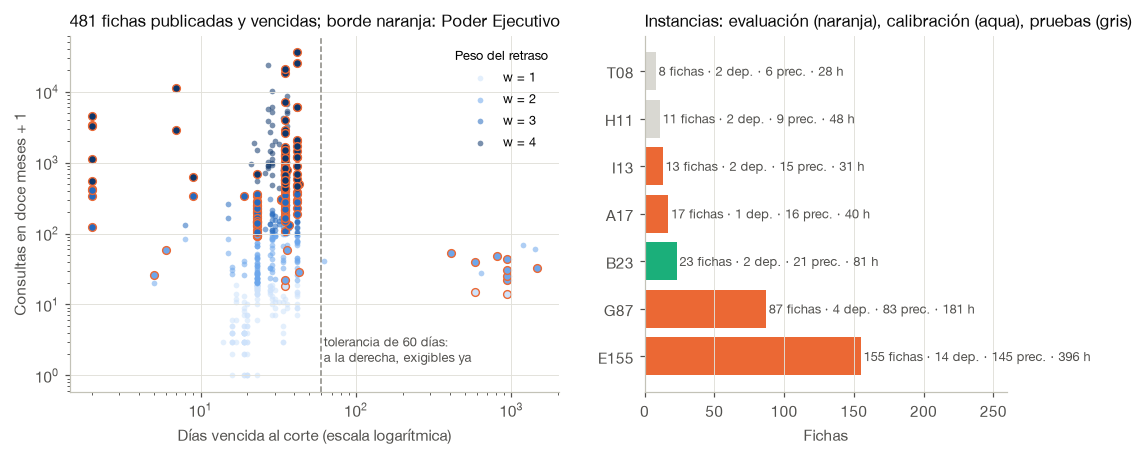

In [31]:
# Figura 1 — las fichas vencidas y las instancias
COLOR_W = {1: RAMPA_AZUL[0], 2: RAMPA_AZUL[2], 3: RAMPA_AZUL[4], 4: RAMPA_AZUL[6]}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.35, 1]})
pe_mask = FICHAS["orden_gobierno"] == "Poder Ejecutivo"
for w_ in (1, 2, 3, 4):
    m = FICHAS["w"] == w_
    ax1.scatter(FICHAS.loc[m & ~pe_mask, "dias_vencida"], FICHAS.loc[m & ~pe_mask, "consultas_12m"] + 1, s=14, color=COLOR_W[w_],
                alpha=0.55, linewidths=0, label=f"w = {w_}")
    ax1.scatter(FICHAS.loc[m & pe_mask, "dias_vencida"], FICHAS.loc[m & pe_mask, "consultas_12m"] + 1, s=26, facecolor=COLOR_W[w_],
                edgecolor=NARANJA, linewidths=0.9)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Días vencida al corte (escala logarítmica)")
ax1.set_ylabel("Consultas en doce meses + 1")
ax1.axvline(60, color=TENUE, lw=1, ls="--")
ax1.text(62, 1.4, "tolerancia de 60 días:\na la derecha, exigibles ya", color=TINTA_2, fontsize=8.5, va="bottom")
ax1.set_title("481 fichas publicadas y vencidas; borde naranja: Poder Ejecutivo", loc="left")
ax1.legend(title="Peso del retraso", fontsize=8.5, title_fontsize=8.5, loc="upper right")
orden = ["T08", "H11", "I13", "A17", "B23", "G87", "E155"]
y = np.arange(len(orden))
ax2.barh(y, [INSTANCIAS[k].n for k in orden], color=[NARANJA if k in EVALUACION else (AQUA if k == CALIBRACION else GRIS_CLARO) for k in orden])
for i, k in enumerate(orden):
    I_ = INSTANCIAS[k]
    ax2.text(I_.n + 2, i, f"{I_.n} fichas · {len(I_.dependencias)} dep. · {len(I_.pred)} prec. · {I_.p.sum():.0f} h", va="center", fontsize=8.5, color=TINTA_2)
ax2.set_yticks(y, orden)
ax2.invert_yaxis()
ax2.set_xlim(0, 260)
ax2.set_xlabel("Fichas")
ax2.grid(axis="y", visible=False)
ax2.set_title("Instancias: evaluación (naranja), calibración (aqua), pruebas (gris)", loc="left")
fig.savefig(FIGURAS / "ae_a05_01_datos_instancias.png")
plt.show()

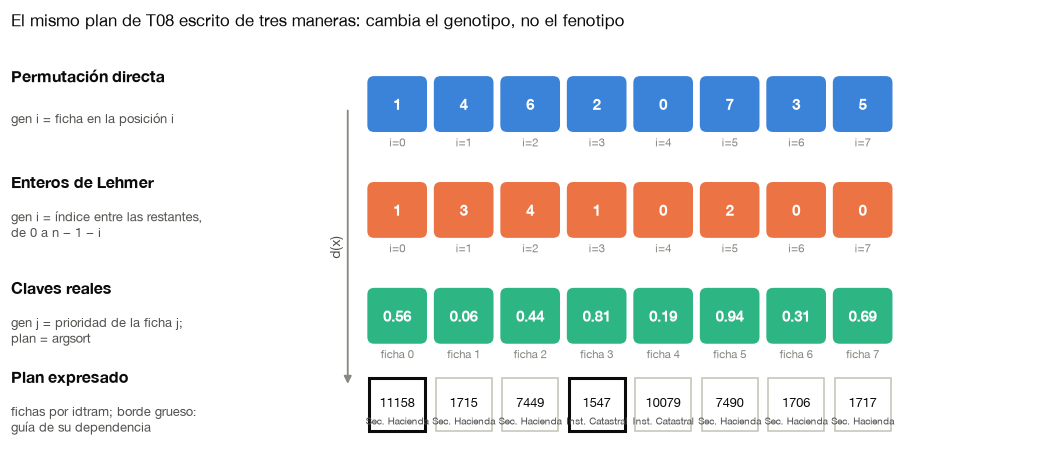

In [32]:
# Figura 2 — un mismo plan en tres codificaciones y la cadena genotipo → plan → plan reparado
I = INSTANCIAS["T08"]
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 4.8)
ax.axis("off")
plan = EJEMPLO_COMUN["plan"]
ABREV_DEP = {"Secretaría de Hacienda": "Sec. Hacienda", "Instituto Catastral": "Inst. Catastral"}
filas_ = [("Permutación directa", [str(f) for f in EJEMPLO_COMUN["permutacion"]], AZUL, "gen i = ficha en la posición i"),
          ("Enteros de Lehmer", [str(l) for l in EJEMPLO_COMUN["lehmer"]], NARANJA, "gen i = índice entre las restantes,\nde 0 a n − 1 − i"),
          ("Claves reales", [f"{k:.2f}" for k in EJEMPLO_COMUN["claves"]], AQUA, "gen j = prioridad de la ficha j;\nplan = argsort")]
X0 = 4.2
for r_, (titulo, genes, color, nota) in enumerate(filas_):
    y0 = 3.9 - r_ * 1.25
    ax.text(0.0, y0 + 0.42, titulo, fontsize=10.5, color=TINTA, weight="bold", va="center")
    ax.text(0.0, y0 - 0.08, nota, fontsize=8.5, color=TINTA_2, va="center")
    for i, g in enumerate(genes):
        x0 = X0 + i * 0.78
        ax.add_patch(FancyBboxPatch((x0, y0 - 0.22), 0.66, 0.62, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    facecolor=color, edgecolor="none", alpha=0.92))
        ax.text(x0 + 0.33, y0 + 0.09, g, ha="center", va="center", color="white", fontsize=10, weight="bold")
        etiqueta = f"i={i}" if r_ < 2 else f"ficha {i}"
        ax.text(x0 + 0.33, y0 - 0.36, etiqueta, ha="center", va="center", color=TENUE, fontsize=7.5)
# El plan común, abajo, con dependencia y precedencias.
y0 = 0.35
ax.text(0.0, y0 + 0.42, "Plan expresado", fontsize=10.5, color=TINTA, weight="bold", va="center")
ax.text(0.0, y0 - 0.08, "fichas por idtram; borde grueso:\nguía de su dependencia", fontsize=8.5, color=TINTA_2, va="center")
for i, f in enumerate(plan):
    x0 = X0 + i * 0.78
    es_guia = f in I.guias
    ax.add_patch(Rectangle((x0, y0 - 0.22), 0.66, 0.62, facecolor="white", edgecolor=TINTA if es_guia else EJE, linewidth=2.0 if es_guia else 1.0))
    ax.text(x0 + 0.33, y0 + 0.12, I.ids[f], ha="center", va="center", color=TINTA, fontsize=8.5)
    ax.text(x0 + 0.33, y0 - 0.1, ABREV_DEP.get(I.dependencias[I.dep[f]], I.dependencias[I.dep[f]][:12]), ha="center", va="center", color=TINTA_2, fontsize=6.5)
ax.annotate("", xy=(X0 - 0.25, 0.65), xytext=(X0 - 0.25, 3.95), arrowprops=dict(arrowstyle="-|>", color=TENUE, lw=1.2))
ax.text(X0 - 0.4, 2.3, "d(x)", rotation=90, color=TINTA_2, fontsize=9, ha="center", va="center")
ax.set_title("El mismo plan de T08 escrito de tres maneras: cambia el genotipo, no el fenotipo", loc="left")
fig.savefig(FIGURAS / "ae_a05_02_codificaciones.png")
plt.show()

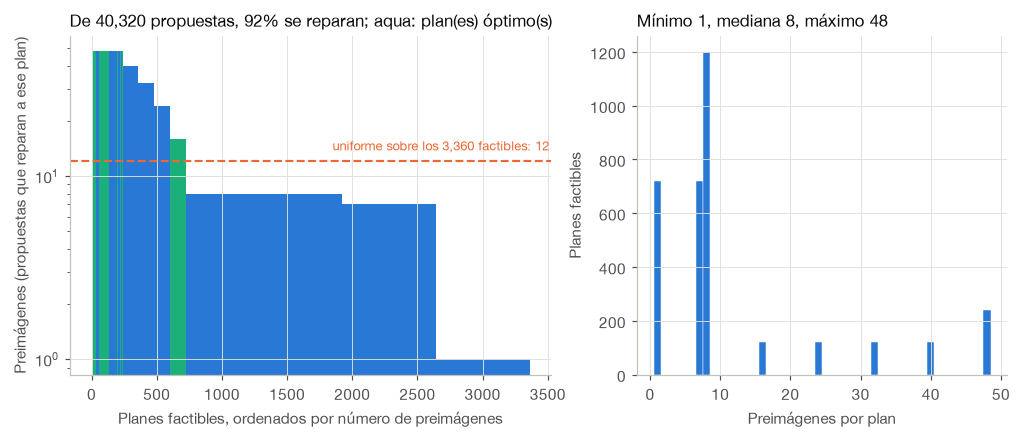

In [33]:
# Figura 3 — sesgo de reparación en T08: preimágenes por plan factible
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.3, 1]})
conteos = np.sort(preimagenes)[::-1]
ax1.bar(np.arange(len(conteos)), conteos, width=1.0, color=AZUL, linewidth=0)
ax1.axhline(len(TODAS_T08) / len(planes_u), color=NARANJA, lw=1.4, ls="--")
ax1.text(len(conteos) * 0.55, len(TODAS_T08) / len(planes_u) * 1.15, f"uniforme sobre los {len(planes_u):,} factibles: {len(TODAS_T08) / len(planes_u):.0f}",
         color=NARANJA, fontsize=8.5)
for o in optimos:
    pos_o = int(np.flatnonzero(np.argsort(preimagenes)[::-1] == o)[0])
    ax1.bar([pos_o], [preimagenes[o]], width=3.0, color=AQUA)
ax1.set_yscale("log")
ax1.set_xlabel("Planes factibles, ordenados por número de preimágenes")
ax1.set_ylabel("Preimágenes (propuestas que reparan a ese plan)")
ax1.set_title(f"De {len(TODAS_T08):,} propuestas, {RESUMEN_SESGO['fraccion_reparada']:.0%} se reparan; aqua: plan(es) óptimo(s)", loc="left")
ax2.hist(preimagenes, bins=np.arange(0.5, preimagenes.max() + 1.5, 1), color=AZUL, edgecolor="white", linewidth=0.3)
ax2.set_xlabel("Preimágenes por plan")
ax2.set_ylabel("Planes factibles")
ax2.set_title(f"Mínimo {RESUMEN_SESGO['preimagenes_min']}, mediana {RESUMEN_SESGO['preimagenes_mediana']:.0f}, máximo {RESUMEN_SESGO['preimagenes_max']}", loc="left")
fig.savefig(FIGURAS / "ae_a05_03_sesgo_reparacion.png")
plt.show()

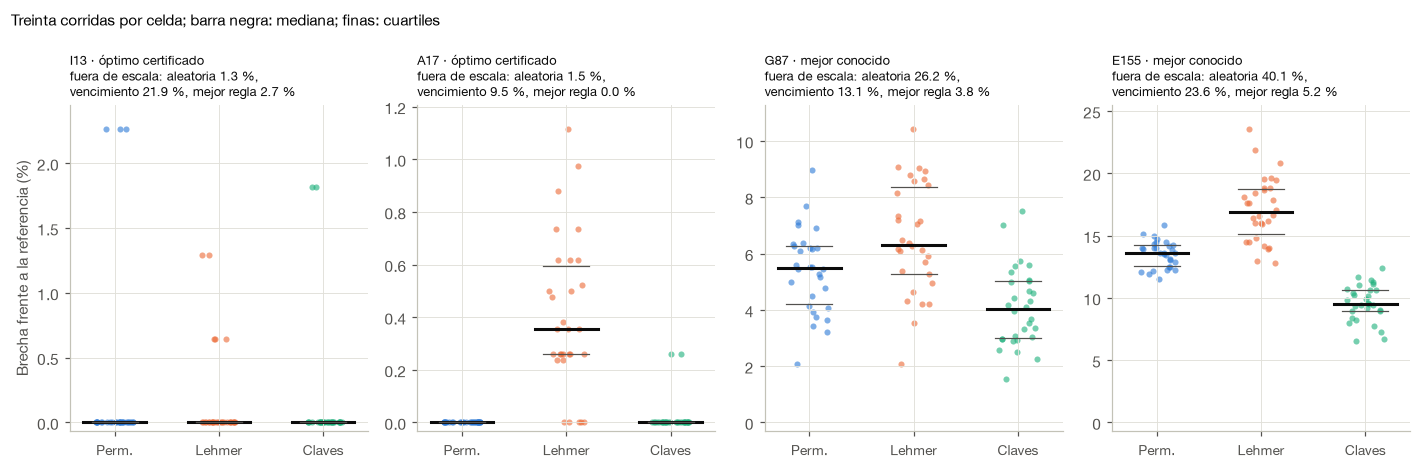

In [34]:
# Figura 4 — brecha final por instancia y representación, con la búsqueda aleatoria y la regla de vencimiento
fig, axes = plt.subplots(1, 4, figsize=(13, 4.3), sharey=False)
rng_f = np.random.default_rng(0)
for ax, nombre in zip(axes, EVALUACION):
    df = corridas[corridas["instancia"] == nombre]
    for j, rep in enumerate(REPRESENTACIONES):
        v = df.loc[df["representacion"] == rep, "brecha_pct"].to_numpy()
        ax.scatter(j + rng_f.uniform(-0.18, 0.18, len(v)), v, s=16, color=COLOR[rep], alpha=0.6, linewidths=0)
        q1, q2, q3 = np.percentile(v, [25, 50, 75])
        ax.plot([j - 0.3, j + 0.3], [q2, q2], color=TINTA, lw=2.0)
        ax.plot([j - 0.22, j + 0.22], [q1, q1], color=TINTA_2, lw=0.8)
        ax.plot([j - 0.22, j + 0.22], [q3, q3], color=TINTA_2, lw=0.8)
    ba_med = aleatoria.loc[aleatoria["instancia"] == nombre, "brecha_pct"].median()
    venc = float(resumen.loc[resumen["instancia"] == nombre, "vencimiento_brecha_pct"].iloc[0])
    regla = float(resumen.loc[resumen["instancia"] == nombre, "mejor_regla_brecha_pct"].iloc[0])
    ax.set_xticks(range(3), ["Perm.", "Lehmer", "Claves"], fontsize=9)
    ax.set_title(f"{nombre} · {ORIGEN_REFERENCIA[nombre].split(' (')[0]}\nfuera de escala: aleatoria {ba_med:.1f} %,\nvencimiento {venc:.1f} %, mejor regla {regla:.1f} %",
                 loc="left", fontsize=8.5)
    tope = max(1e-9, df["brecha_pct"].max())
    ax.set_ylim(-0.03 * tope, 1.08 * tope)
    if nombre == EVALUACION[0]:
        ax.set_ylabel("Brecha frente a la referencia (%)")
fig.suptitle("Treinta corridas por celda; barra negra: mediana; finas: cuartiles", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURAS / "ae_a05_04_brechas.png")
plt.show()

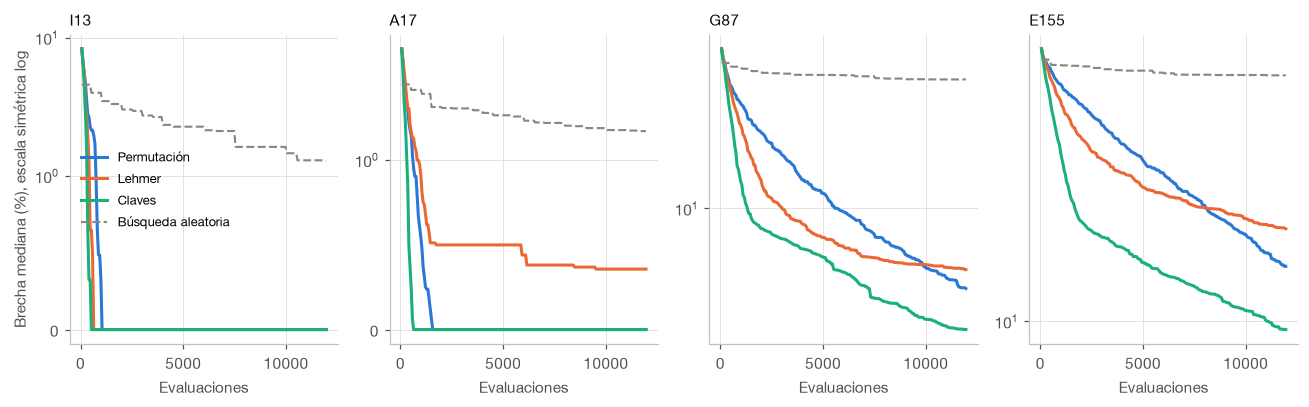

In [35]:
# Figura 5 — convergencia: brecha mediana de la mejor solución frente a evaluaciones
fig, axes = plt.subplots(1, 4, figsize=(12, 3.8))
for ax, nombre in zip(axes, EVALUACION):
    for rep in REPRESENTACIONES:
        m = mecanismo[(mecanismo["instancia"] == nombre) & (mecanismo["representacion"] == rep)]
        ax.plot(m["evaluaciones"], m["brecha_pct"], color=COLOR[rep], label=CORTO[rep])
    mb = mecanismo_ba[mecanismo_ba["instancia"] == nombre]
    ax.plot(mb["evaluaciones"], mb["brecha_pct"], color=TENUE, ls="--", lw=1.4, label="Búsqueda aleatoria")
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_xlabel("Evaluaciones")
    ax.set_title(nombre, loc="left", fontsize=10)
    if nombre == EVALUACION[0]:
        ax.set_ylabel("Brecha mediana (%), escala simétrica log")
        ax.legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURAS / "ae_a05_05_convergencia.png")
plt.show()

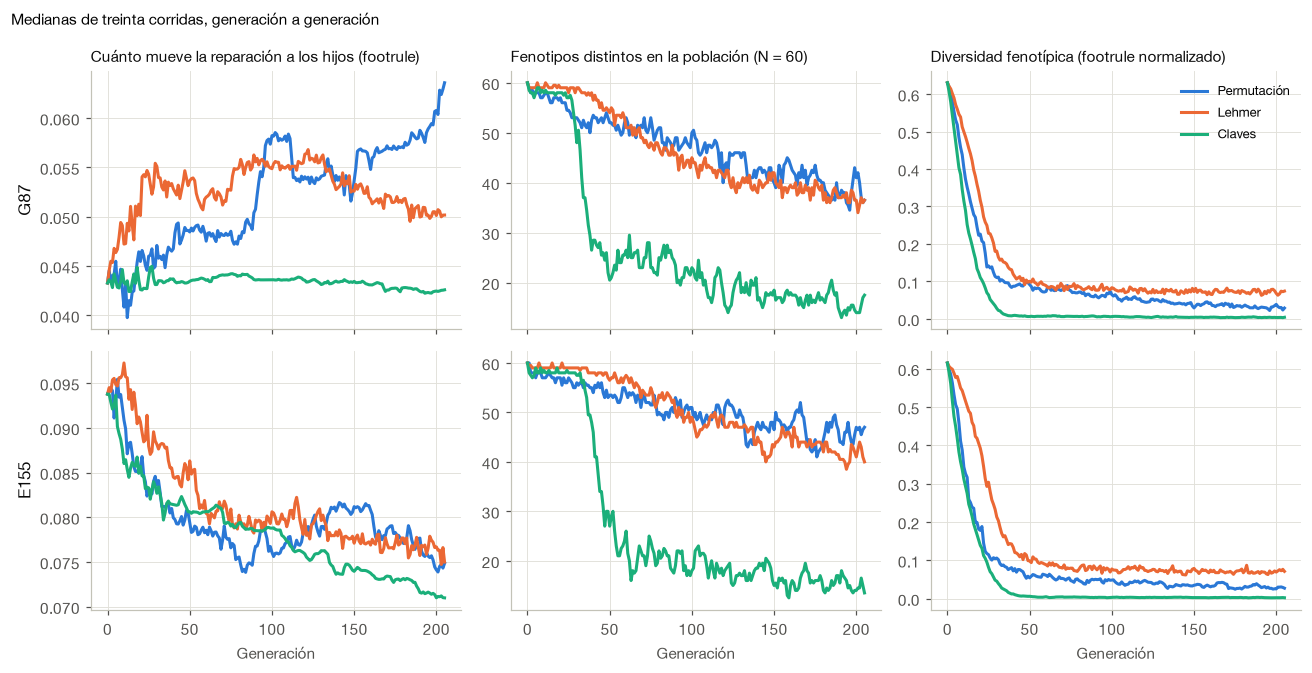

In [36]:
# Figura 6 — mecanismo en G87 y E155: cuánto mueve la reparación, fenotipos distintos y diversidad fenotípica
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharex="col")
for fila, nombre in enumerate(("G87", "E155")):
    for col, (medida, etiqueta) in enumerate((("desplazamiento_reparacion", "Cuánto mueve la reparación a los hijos (footrule)"),
                                              ("fenotipos_distintos", f"Fenotipos distintos en la población (N = {N_POB})"),
                                              ("diversidad_fenotipica", "Diversidad fenotípica (footrule normalizado)"))):
        ax = axes[fila, col]
        for rep in REPRESENTACIONES:
            m = mecanismo[(mecanismo["instancia"] == nombre) & (mecanismo["representacion"] == rep)]
            ax.plot(m["generacion"], m[medida], color=COLOR[rep], label=CORTO[rep])
        if fila == 0:
            ax.set_title(etiqueta, loc="left", fontsize=10)
        if fila == 1:
            ax.set_xlabel("Generación")
        if col == 0:
            ax.set_ylabel(nombre, fontsize=11, color=TINTA)
axes[0, 2].legend(fontsize=8.5, loc="upper right")
fig.suptitle("Medianas de treinta corridas, generación a generación", x=0.01, ha="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURAS / "ae_a05_06_mecanismo.png")
plt.show()

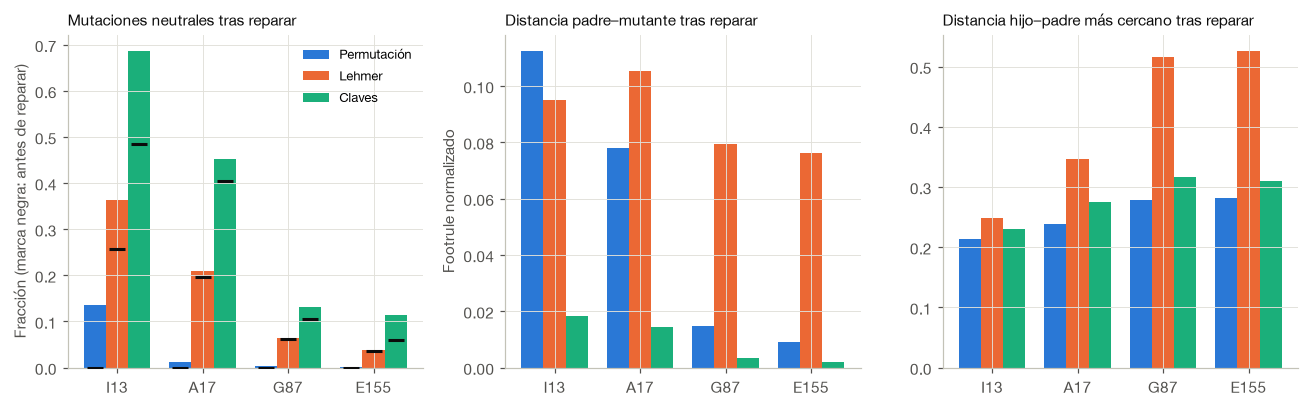

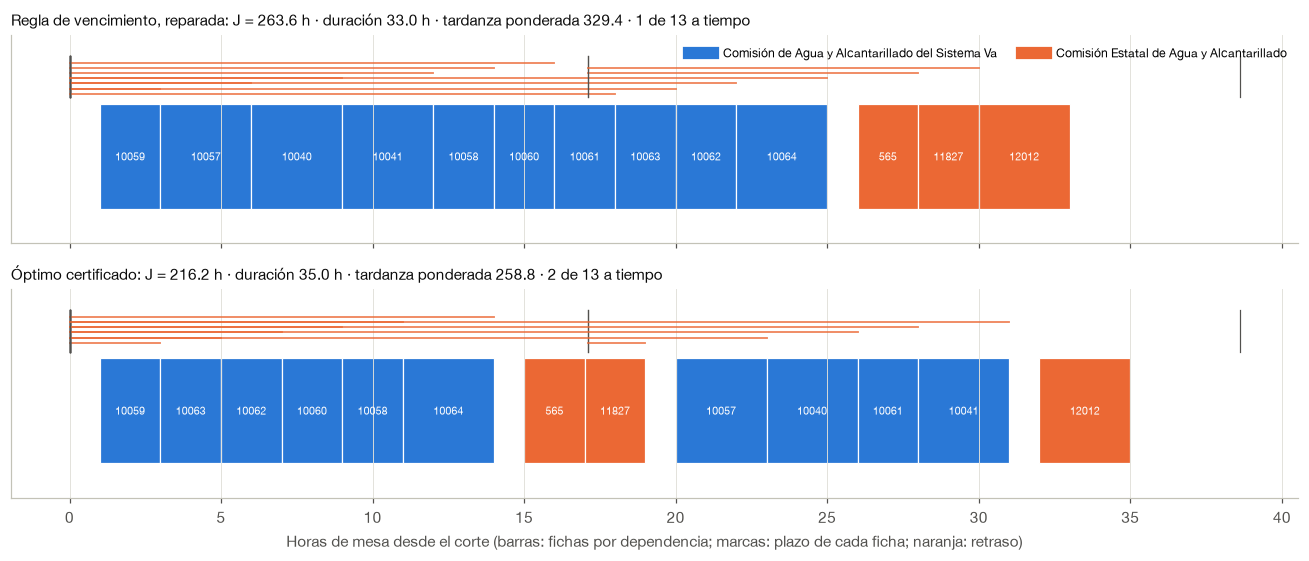

In [37]:
# Figura 7 — localidad y neutralidad de los operadores por instancia
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
ancho = 0.26
for ax, (medida, etiqueta) in zip(axes, (("neutralidad_despues", "Mutaciones neutrales tras reparar"),
                                         ("localidad_mutacion_todas", "Distancia padre–mutante tras reparar"),
                                         ("distancia_hijo_padre_cercano", "Distancia hijo–padre más cercano tras reparar"))):
    for j, rep in enumerate(REPRESENTACIONES):
        v = [float(LOCALIDAD[(LOCALIDAD["instancia"] == k) & (LOCALIDAD["representacion"] == rep)][medida].iloc[0]) for k in EVALUACION]
        ax.bar(np.arange(len(EVALUACION)) + (j - 1) * ancho, v, ancho, color=COLOR[rep], label=CORTO[rep])
        if medida == "neutralidad_despues":
            v0 = [float(LOCALIDAD[(LOCALIDAD["instancia"] == k) & (LOCALIDAD["representacion"] == rep)]["neutralidad_antes"].iloc[0]) for k in EVALUACION]
            ax.scatter(np.arange(len(EVALUACION)) + (j - 1) * ancho, v0, marker="_", s=120, color=TINTA, zorder=3)
    ax.set_xticks(range(len(EVALUACION)), EVALUACION)
    ax.set_title(etiqueta, loc="left", fontsize=10)
axes[0].set_ylabel("Fracción (marca negra: antes de reparar)")
axes[1].set_ylabel("Footrule normalizado")
axes[0].legend(fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURAS / "ae_a05_07_localidad_neutralidad.png")
plt.show()

# Figura 8 — caso I13: regla de vencimiento frente al óptimo certificado
I13 = INSTANCIAS["I13"]
COLOR_DEP = {g: c for g, c in zip(range(len(I13.dependencias)), (AZUL, NARANJA, AQUA))}
fig, axes = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True)
for ax, (metodo, titulo) in zip(axes, (("vencimiento", "Regla de vencimiento, reparada"), ("óptimo", "Óptimo certificado"))):
    d_ = caso_i13[caso_i13["metodo"] == metodo].reset_index(drop=True)
    r_ = evaluar_planes(I13, np.array([[I13.ids.index(i) for i in d_["idtram"]]]))
    for _, fila in d_.iterrows():
        f = I13.ids.index(fila["idtram"])
        inicio_ = fila["C"] - fila["p"]
        ax.add_patch(Rectangle((inicio_, 0.2), fila["p"], 0.6, facecolor=COLOR_DEP[int(I13.dep[f])], edgecolor="white", linewidth=0.8))
        ax.text(inicio_ + fila["p"] / 2, 0.5, fila["idtram"], ha="center", va="center", fontsize=7, color="white", rotation=90 if fila["p"] < 1.6 else 0)
        ax.plot([fila["d"], fila["d"]], [0.84, 1.08], color=TINTA_2, lw=0.8)
        if fila["T"] > 0:
            ax.plot([fila["d"], fila["C"]], [0.86 + 0.03 * (fila["orden"] % 7)] * 2, color=NARANJA, lw=1.2, alpha=0.8)
    ax.set_ylim(0, 1.2)
    ax.set_yticks([])
    ax.set_title(f"{titulo}: J = {r_['J'][0]:.1f} h · duración {r_['Cmax'][0]:.1f} h · tardanza ponderada {r_['tardanza_ponderada'][0]:.1f} · "
                 f"{int((r_['T'][0] == 0).sum())} de 13 a tiempo", loc="left", fontsize=10)
axes[1].set_xlabel("Horas de mesa desde el corte (barras: fichas por dependencia; marcas: plazo de cada ficha; naranja: retraso)")
leyenda = [Line2D([0], [0], color=COLOR_DEP[g], lw=8, label=I13.dependencias[g][:48]) for g in COLOR_DEP]
axes[0].legend(handles=leyenda, fontsize=8, loc="upper right", ncol=2)
fig.tight_layout()
fig.savefig(FIGURAS / "ae_a05_08_caso_i13.png")
plt.show()

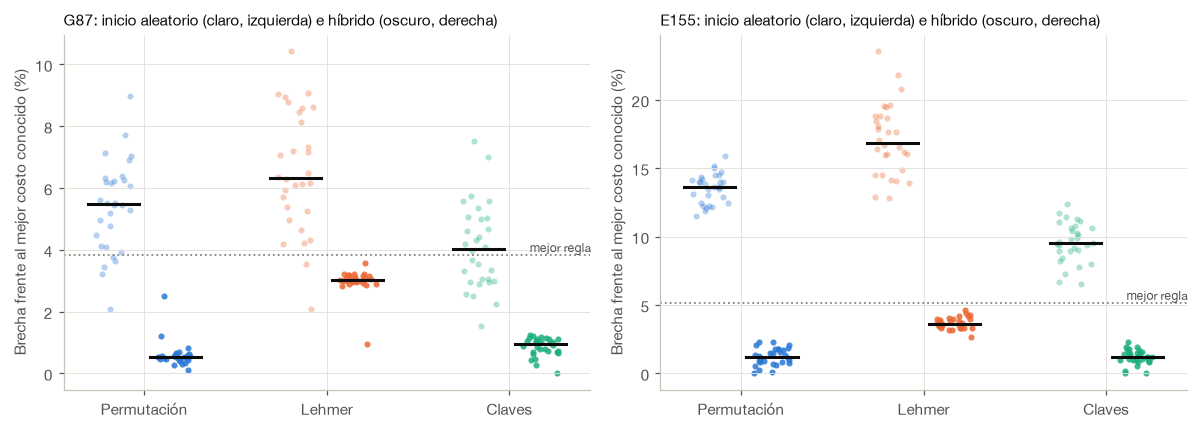

In [38]:
# Figura 9 — inicio aleatorio frente a inicio híbrido en G87 y E155
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rng_f = np.random.default_rng(1)
for ax, nombre in zip(axes, GRANDES):
    for j, rep in enumerate(REPRESENTACIONES):
        for desplaza, df_, alpha in ((-0.17, corridas, 0.35), (0.17, corridas_hibrido, 0.85)):
            v = df_.loc[(df_["instancia"] == nombre) & (df_["representacion"] == rep), "brecha_pct"].to_numpy()
            x = j + desplaza + rng_f.uniform(-0.1, 0.1, len(v))
            ax.scatter(x, v, s=16, color=COLOR[rep], alpha=alpha, linewidths=0)
            ax.plot([j + desplaza - 0.14, j + desplaza + 0.14], [np.median(v)] * 2, color=TINTA, lw=2)
    regla = 100 * (LINEAS.loc[LINEAS["instancia"] == nombre, "J"].min() - REFERENCIA[nombre]) / REFERENCIA[nombre]
    ax.axhline(regla, color=TENUE, lw=1.2, ls=":")
    ax.text(2.45, regla, "mejor regla", color=TINTA_2, fontsize=8, va="bottom", ha="right")
    ax.set_xticks(range(3), [CORTO[r] for r in REPRESENTACIONES])
    ax.set_title(f"{nombre}: inicio aleatorio (claro, izquierda) e híbrido (oscuro, derecha)", loc="left", fontsize=10)
    ax.set_ylabel("Brecha frente al mejor costo conocido (%)")
fig.tight_layout()
fig.savefig(FIGURAS / "ae_a05_09_inicio_hibrido.png")
plt.show()

## O. Manifiesto de trazabilidad

Registra versiones, configuración, parámetros calibrados, semillas, referencias, la representación elegida y la huella SHA-256 de cada archivo de resultados y de cada figura, incluido el CSV de datos.

In [39]:
def sha256(ruta: Path) -> str:
    return hashlib.sha256(ruta.read_bytes()).hexdigest()


manifiesto = {
    "actividad": "AAEE · Actividad 05 · corte 2",
    "entorno": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
                "scipy": scipy.__version__, "matplotlib": matplotlib.__version__, "plataforma": platform.platform()},
    "datos": {"archivo": "datos/fichas_vencidas.csv", "fichas": int(len(FICHAS)), "corte": "2026-08-12", "folio_pnt": "130213100101626",
              "sha256": sha256(DATOS / "fichas_vencidas.csv")},
    "modelo": {"alistamiento_h": ALISTAMIENTO, "lambda": LAMBDA},
    "etapas_comunes": {"2": "M05 sobre el plan reparado", "3": "M12 (k = 3)", "6": f"M22 (e = {ELITE})", "7": f"M26 (E_max = {E_MAX})"},
    "etapas_por_representacion": {rep: {"1": "M01 emparejada", "4": NOMBRE_CRUCE[rep], "5": NOMBRE_MUTACION[rep]} for rep in REPRESENTACIONES},
    "comunes": {"N": N_POB, "k": 3, "e": ELITE, "pc": 0.9, "E_max": E_MAX, "evaluaciones": EVALUACIONES_AG, "generaciones": GENERACIONES},
    "rejilla_calibracion": REJILLA, "parametros_calibrados": PARAMETROS,
    "semillas_calibracion": SEMILLAS_CALIBRACION, "semillas_evaluacion": SEMILLAS,
    "instancias": {k: {"descripcion": INSTANCIAS[k].descripcion, "n": INSTANCIAS[k].n, "dependencias": len(INSTANCIAS[k].dependencias),
                       "precedencias": int(len(INSTANCIAS[k].pred)), "ids": list(INSTANCIAS[k].ids)} for k in INSTANCIAS},
    "optimos": {k: e_["J"] for k, e_ in EXACTOS.items()},
    "referencias": {k: {"J": REFERENCIA[k], "origen": ORIGEN_REFERENCIA[k]} for k in EVALUACION},
    "sesgo_t08": RESUMEN_SESGO,
    "elegida": ELEGIDA,
    "experimento_secundario": {"inicio": "híbrido, 35 % heurístico", "instancias": GRANDES, "corridas": int(len(corridas_hibrido))},
    "pruebas": int(len(tabla_pruebas)),
    "segundos_totales": time.perf_counter() - INICIO_CUADERNILLO,
    "archivos": {str(r): sha256(r) for r in sorted(list(RESULTADOS.glob("*.csv")) + list(FIGURAS.glob("*.png")))},
}
(RESULTADOS / "manifiesto.json").write_text(json.dumps(manifiesto, indent=2, ensure_ascii=False, default=float))
print(f"Manifiesto con {len(manifiesto['archivos'])} archivos · ejecución completa en {manifiesto['segundos_totales']:.0f} s")

Manifiesto con 31 archivos · ejecución completa en 149 s
